# Лабораторная работа № 5. Рекуррентные нейронные сети и представления текста

**Тема:** обработка последовательностей, токенизация, векторные представления слов, рекуррентные нейронные сети, LSTM и GRU.

**Цель:** изучить принципы обработки последовательных данных, научиться преобразовывать текст в последовательности токенов и освоить базовые рекуррентные архитектуры для классификации текстов.

В этой работе мы будем решать задачу классификации новостных текстов на четыре тематические категории. Сначала построим простую модель, которая усредняет векторные представления токенов. Затем добавим рекуррентную обработку и сравним обычную RNN с LSTM и GRU.

Для текста недостаточно знать, какие слова встретились в документе. Порядок слов может менять смысл:

- `the dog chased the cat`;
- `the cat chased the dog`.

Набор слов почти одинаков, но роли объектов различаются. Вопрос этой работы: как передать модели информацию о порядке токенов и контексте?

In [ ]:
# Проверяем версии библиотек и выбираем устройство, на котором будут выполняться вычисления.
import sys
import platform
import torch

# Сначала фиксируем версии среды: это помогает понять, какие возможности PyTorch и CUDA доступны.
print(f"Python: {sys.version.split()[0]}")
print(f"Платформа: {platform.platform()}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA доступна: {torch.cuda.is_available()}")
print(f"CUDA-сборка PyTorch: {torch.version.cuda}")

# Выбираем единое устройство для дальнейших вычислений; при отсутствии CUDA используем CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство для вычислений: {device}")

# Дополнительные сведения о видеокарте выводим только тогда, когда CUDA действительно доступна.
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA-устройств: {torch.cuda.device_count()}")

## Что было рассмотрено в предыдущих лабораторных работах

В работах № 1-4 мы рассматривали данные, в которых важна пространственная структура: изображение состоит из пикселей, расположенных в двумерной сетке. Теперь перейдём к данным, для которых важен **порядок элементов**. Текст, аудиосигнал и временной ряд - примеры последовательностей: значение текущего элемента часто зависит от того, что было до него.

В лабораторной работе № 4 мы изучали латентные представления: сеть преобразовывала изображение в компактный вектор и восстанавливала его. Теперь будем изучать не только итоговый вектор объекта, но и способ его построения из **упорядоченной последовательности**.

## Последовательности и временная структура данных

Последовательность - упорядоченный набор элементов:

$$
X=(x_1,x_2,\ldots,x_T),
$$

где $T$ - длина последовательности, а $x_t$ - элемент на позиции $t$.

Индекс $t$ можно трактовать как время, позицию слова в предложении или шаг обработки сигнала. В отличие от независимых строк таблицы, элементы последовательности часто связаны: при анализе слова полезно учитывать предыдущие слова, а при прогнозировании временного ряда - предыдущие измерения.

**Примеры последовательностей:**

- текст: слова или подслова в предложении;
- аудио: последовательность отсчётов или акустических кадров;
- временной ряд: значения датчика по времени;
- видео: последовательность кадров.

В этой работе будем использовать текст. Для простоты каждый элемент последовательности будет соответствовать одному токену.

## Постановка задачи: классификация новостей

Каждой новости соответствует текст и одна метка класса. Модель должна получить текст и вернуть принадлежность новости классу.

Используем AG News - набор англоязычных новостных заголовков и описаний. В нём четыре класса:

| Метка | Категория |
|---:|---|
| 0 | World - мировые новости |
| 1 | Sports - спорт |
| 2 | Business - бизнес |
| 3 | Sci/Tech - наука и технологии |

В опубликованном наборе 120 000 объектов в train и 7 600 объектов в test. Поле `text` содержит текст, а `label` - целочисленную метку.

Из-за большой сложности обучения рассматриваемых в работе моделей возьмём 40 000 текстов для обучения и по 10 000 для валидации и теста.

## Загрузка и первичный осмотр AG News

Сначала загрузим исходные разбиения. Объединим все сплиты в один и уже после разобъём его на train/validation/test.

Будем использовать `train_test_split` из Hugging Face Datasets. Укажем seed и стратификацию по метке: это помогает сохранить близкие доли четырёх классов.

In [ ]:
# Фиксируем seed и задаём основные гиперпараметры эксперимента в одном месте.
from pathlib import Path
import random
import numpy as np

SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 10
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DATA_DIR = Path("./data")

DATA_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [ ]:
# Загружаем AG News и разбиваем на train/validation/test.
from datasets import load_dataset


ds = load_dataset("wangrongsheng/ag_news", split="train+test")

train_test = ds.train_test_split(
    train_size=50_000,
    test_size=10_000,
    seed=SEED,
    stratify_by_column="label",
)

train_validation = train_test["train"].train_test_split(
    train_size=40_000,
    test_size=10_000,
    seed=SEED,
    stratify_by_column="label",
)

train = train_validation["train"]
validation = train_validation["test"]
test = train_test["test"]

print("Train:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))
print("Признаки:", test.features)

Train: 40000
Validation: 10000
Test: 10000
Признаки: {'text': Value('string'), 'label': ClassLabel(names=['World', 'Sports', 'Business', 'Sci/Tech'])}


In [84]:
# Выводим несколько новостных текстов и меток, чтобы понять формат примеров.
import pandas as pd


examples = pd.DataFrame(
    [
        {"text": train[index]["text"], "label": train[index]["label"]}
        for index in range(10)
    ]
)
examples

,text,label
0,Would You Hire A Hacker? theodp writes quot;A...,3
1,Mbeki goes into Ivory Coast peace talks BOUAKE...,0
2,Japan Shuts Citigroup Private Bank Unit Japan ...,2
3,Former Kan. Junior College Coach Indicted WICH...,1
4,Weah returns to Liberia Liberian legend George...,0
5,Labour MPs urge Iraq troop vote 45 Labour MPs ...,0
6,IBM: Practice Makes Perfect for the SOA Initia...,3
7,Bush to press APEC leaders on N. Korea North K...,0
8,Affiliated Managers to acquire AQR stake Affil...,2
9,Chuck stops here AUSTRALIA #39;s elite cricket...,1


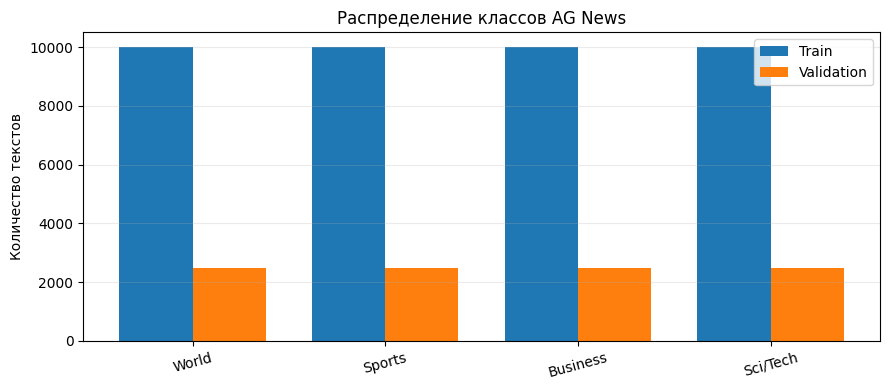

In [85]:
# Получаем названия классов из метаданных датасета и проверяем распределение меток.
from matplotlib import pyplot as plt


label_feature = train.features["label"]
CLASS_NAMES = (
    label_feature.names
    if hasattr(label_feature, "names")
    else ["World", "Sports", "Business", "Sci/Tech"]
)

train_counts = np.bincount(np.asarray(train["label"]), minlength=len(CLASS_NAMES))
validation_counts = np.bincount(
    np.asarray(validation["label"]), minlength=len(CLASS_NAMES)
)

fig, ax = plt.subplots(figsize=(9, 4))
positions = np.arange(len(CLASS_NAMES))

width = 0.38
ax.bar(positions - width / 2, train_counts, width, label="Train")
ax.bar(positions + width / 2, validation_counts, width, label="Validation")
ax.set_xticks(positions, CLASS_NAMES, rotation=15)
ax.set_ylabel("Количество текстов")
ax.set_title("Распределение классов AG News")
ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

## От текста к последовательности токенов

Нейросеть не получает слова как готовые смысловые объекты. Сначала текст нужно разбить на **токены** - единицы, которые модель будет обрабатывать. В этой работе используем простую токенизацию на уровне слов:

1. приводим текст к нижнему регистру;
2. выделяем последовательности букв и цифр с помощью регулярного выражения;
3. каждому токену сопоставляем целочисленный индекс.

Например, фраза `New technology improves communication!` превращается в последовательность токенов:

```text
["new", "technology", "improves", "communication"]
```

А после построения словаря - в последовательность целых чисел:

```text
[17, 842, 91, 1530]
```

Номера здесь условны: они зависят от частот слов в обучающей выборке и параметров словаря.

Такая токенизация проста и наглядна, но имеет ограничения: разные словоформы считаются разными токенами, редкие слова могут стать неизвестными, а составные слова не разбиваются на подслова. 

### Словарь и специальные токены

Словарь (`Vocabulary`) связывает токены с целочисленными индексами. Два специальных токена понадобятся почти при любой схеме обработки текста:

- **`<PAD>`** - заполнитель для выравнивания последовательностей разной длины. Зарезервируем индекс `0`.
- **`<UNK>`** - неизвестный токен для слов, которых нет в словаре. Зарезервируем индекс `1`.

Словарь строим **только по train**. Если включить тексты validation или test, информация о распределении слов в отложенных данных попадёт в подготовку признаков. Даже если метки не используются, лучше соблюдать единое правило отсутствия утечки данных.

Редкие слова отбрасываем по `min_freq`, а размер словаря ограничиваем `max_size`. Это уменьшает объём embedding-таблицы и позволяет контролировать число параметров.

In [9]:
# Реализуем простой словарь: частотный отбор, специальные токены, кодирование и декодирование.
from collections import Counter
import re


class Vocabulary:
    """Словарь токенов с поддержкой PAD и UNK."""

    def __init__(self, max_size: int = 30_000, min_freq: int = 2) -> None:
        self.max_size = max_size
        self.min_freq = min_freq

        self.pad_token = "<PAD>"
        self.unk_token = "<UNK>"
        self.stoi = {
            self.pad_token: 0,
            self.unk_token: 1,
        }
        self.itos = [self.pad_token, self.unk_token]

    def tokenize(self, text: str) -> list[str]:
        """Разбивает строку на lowercase-токены из букв и цифр."""
        return re.findall(r"\b\w+\b", text.lower())

    def build(self, texts) -> None:
        """Строит словарь по коллекции текстов."""
        counter = Counter()
        for text in texts:
            counter.update(self.tokenize(text))

        words = [
            (word, frequency)
            for word, frequency in counter.most_common()
            if frequency >= self.min_freq and word not in self.stoi
        ]
        words = words[: self.max_size - len(self.stoi)]

        for word, _ in words:
            self.stoi[word] = len(self.itos)
            self.itos.append(word)

    def encode(self, text: str) -> list[int]:
        """Преобразует текст в индексы; пустой текст кодируется как UNK."""
        tokens = self.tokenize(text)
        if not tokens:
            return [self.unk_idx]
        return [self.stoi.get(token, self.unk_idx) for token in tokens]

    def decode(self, token_ids: list[int]) -> list[str]:
        """Преобразует индексы обратно в токены."""
        return [self.itos[index] for index in token_ids]

    def __len__(self) -> int:
        return len(self.itos)

    @property
    def pad_idx(self) -> int:
        return self.stoi[self.pad_token]

    @property
    def unk_idx(self) -> int:
        return self.stoi[self.unk_token]

In [10]:
# Строим словарь только по обучающим текстам и проверяем несколько преобразований.
MAX_VOCAB_SIZE = 30_000
MIN_FREQ = 2

vocab = Vocabulary(max_size=MAX_VOCAB_SIZE, min_freq=MIN_FREQ)
vocab.build(train["text"])

sample_text = train[0]["text"]
sample_tokens = vocab.tokenize(sample_text)
sample_ids = vocab.encode(sample_text)

print("Размер словаря:", len(vocab))
print("Исходный текст:", sample_text[:250], "...")
print("Первые токены:", sample_tokens[:20])
print("Первые индексы:", sample_ids[:20])
print("Обратное преобразование:", vocab.decode(sample_ids[:20]))
print("PAD index:", vocab.pad_idx, "| UNK index:", vocab.unk_idx)

Размер словаря: 28681
Исходный текст: Would You Hire A Hacker? theodp writes  quot;A German security company has divided opinion in the IT industry by offering a job to the teen charged with creating Sasser. ...
Первые токены: ['would', 'you', 'hire', 'a', 'hacker', 'theodp', 'writes', 'quot', 'a', 'german', 'security', 'company', 'has', 'divided', 'opinion', 'in', 'the', 'it', 'industry', 'by']
Первые индексы: [92, 166, 3809, 4, 6788, 1, 3191, 43, 4, 675, 97, 53, 23, 3718, 3236, 6, 2, 19, 254, 20]
Обратное преобразование: ['would', 'you', 'hire', 'a', 'hacker', '<UNK>', 'writes', 'quot', 'a', 'german', 'security', 'company', 'has', 'divided', 'opinion', 'in', 'the', 'it', 'industry', 'by']
PAD index: 0 | UNK index: 1


### Неизвестные слова и ограничение длины

Словарь не обязан содержать каждое слово из корпуса. Слова, которые не встретились в train или оказались слишком редкими, заменяются на `<UNK>`. Проверим долю таких токенов в разных разбиениях.

Кроме того, новости имеют разную длину. Чтобы ограничить расход памяти, зададим `MAX_LENGTH`. Более длинные тексты будем обрезать, а короткие - дополнять `<PAD>` уже внутри батча.

Усечение и padding решают разные задачи:

- **truncation** ограничивает максимальное число токенов в одном примере;
- **padding** приводит последовательности в одном батче к одинаковой длине.

In [11]:
# Оцениваем долю неизвестных токенов и долю текстов, которые будут усечены.
MAX_LENGTH = 160


def unknown_token_share(texts, vocabulary: Vocabulary) -> float:
    unknown = 0
    total = 0
    for text in texts:
        tokens = vocabulary.tokenize(text)
        total += len(tokens)
        unknown += sum(token not in vocabulary.stoi for token in tokens)
    return unknown / max(total, 1)


train_unknown_share = unknown_token_share(train["text"], vocab)
val_unknown_share = unknown_token_share(validation["text"], vocab)
test_unknown_share = unknown_token_share(test["text"], vocab)

train_lengths = np.asarray([len(vocab.tokenize(text)) for text in train["text"]])
truncated_share = np.mean(train_lengths > MAX_LENGTH)

print(f"UNK в train:      {train_unknown_share:.2%}")
print(f"UNK в validation: {val_unknown_share:.2%}")
print(f"UNK в test:       {test_unknown_share:.2%}")
print(f"Текстов длиннее {MAX_LENGTH}: {truncated_share:.2%}")

UNK в train:      0.92%
UNK в validation: 1.89%
UNK в test:       1.88%
Текстов длиннее 160: 0.02%


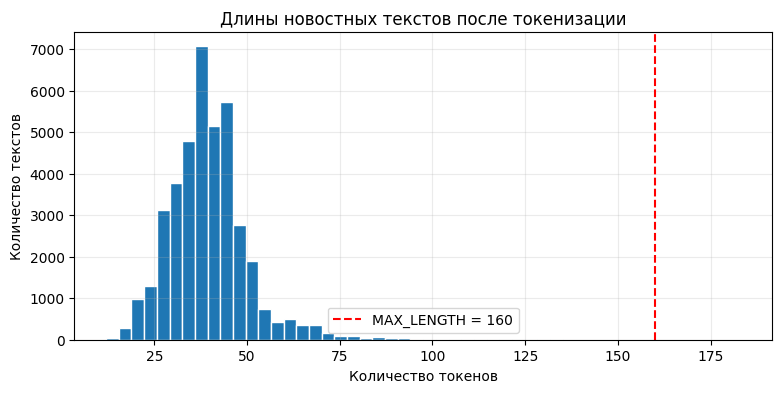

In [12]:
# Визуализируем распределение количества токенов до усечения.
fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(train_lengths, bins=50, edgecolor="white")
ax.axvline(MAX_LENGTH, linestyle="--", color="red", label=f"MAX_LENGTH = {MAX_LENGTH}")
ax.set(
    xlabel="Количество токенов",
    ylabel="Количество текстов",
    title="Длины новостных текстов после токенизации",
)
ax.grid(alpha=0.25)
ax.legend()

plt.show()

**Небольшое исследование.** Как изменится доля усечённых текстов и доля `<UNK>`, если уменьшить `MAX_VOCAB_SIZE` или `MAX_LENGTH`? Объясните, почему слишком маленький словарь и слишком короткая последовательность могут ухудшить классификацию.

## Dataset и подготовка батчей

Один элемент текстового датасета - это последовательность целых индексов и метка класса. На этапе подготовки заранее закодируем тексты, чтобы не выполнять регулярные выражения на каждом шаге обучения.

Для одной модели понадобится выровненная матрица токенов `[B, T]` и длины исходных последовательностей `[B]`. 

In [13]:
# Создаём Dataset, который хранит закодированные последовательности и метки классов.
from torch.utils.data import Dataset, DataLoader


class EncodedTextDataset(Dataset):
    """Тексты AG News, предварительно преобразованные в последовательности индексов."""

    def __init__(self, split, vocabulary: Vocabulary, max_length: int) -> None:
        self.sequences = []
        self.labels = torch.as_tensor(split["label"], dtype=torch.long)

        for text in split["text"]:
            token_ids = vocabulary.encode(text)[:max_length]
            if not token_ids:
                token_ids = [vocabulary.unk_idx]
            self.sequences.append(torch.tensor(token_ids, dtype=torch.long))

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        return self.sequences[index], self.labels[index]


train_dataset = EncodedTextDataset(train, vocab, MAX_LENGTH)
validation_dataset = EncodedTextDataset(validation, vocab, MAX_LENGTH)
test_dataset = EncodedTextDataset(test, vocab, MAX_LENGTH)

print("Train:", len(train_dataset))
print("Validation:", len(validation_dataset))
print("Test:", len(test_dataset))
print("Пример формы последовательности:", tuple(train_dataset[0][0].shape))
print("Пример метки:", train_dataset[0][1].item())

Train: 40000
Validation: 10000
Test: 10000
Пример формы последовательности: (30,)
Пример метки: 3


### Padding и `collate_fn`

В одном батче могут встретиться тексты длиной 20, 35 и 51 токен. Обычный тензор не может хранить такие последовательности в виде прямоугольной матрицы без дополнительной обработки. `pad_sequence` дополняет короткие последовательности значением `pad_idx` до максимальной длины в текущем батче.

Функция `collate_fn` получает список отдельных примеров и формирует один батч. Для рекуррентной модели вернём:

- `tokens`: тензор `[B, T]` с padding;
- `lengths`: исходная длина каждого текста до padding;
- `labels`: метки `[B]`.

Длины нужно сохранить отдельно: рекуррентная сеть не должна воспринимать `<PAD>` как содержательную часть новости.

In [14]:
# Объединяем последовательности разной длины в батч и сохраняем их настоящие длины.
from typing import TypeAlias
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

# Один элемент батча: изображение и соответствующая ему метка.
TensorPair: TypeAlias = tuple[torch.Tensor, torch.Tensor]


def collate_padded(batch: list[TensorPair]) -> tuple[TensorPair, torch.Tensor]:
    sequences, labels = zip(*batch)
    lengths = torch.tensor(
        [sequence.numel() for sequence in sequences], dtype=torch.long
    )

    tokens = pad_sequence(
        sequences,
        batch_first=True,
        padding_value=vocab.pad_idx,
    )
    labels = torch.stack(labels).long()

    return (tokens, lengths), labels

## Векторные представления токенов: `nn.Embedding`

Индекс токена - это только идентификатор. Нельзя считать, что токен с индексом `100` в каком-то смысле «больше» токена с индексом `20`. Чтобы нейросеть могла использовать токены в вычислениях, каждому индексу сопоставляется обучаемый вектор.

`nn.Embedding` можно рассматривать как таблицу параметров:

$$
E\in\mathbb{R}^{|V|\times d},
$$

где $|V|$ - размер словаря, а $d$ - размерность embedding. Для индекса $i$ операция embedding lookup возвращает строку таблицы:

$$
\mathbf{e}_i=E_i\in\mathbb{R}^{d}.
$$

Для батча токенов формы `[B, T]` результат имеет форму `[B, T, d]`. Значения таблицы обучаются вместе с остальными параметрами модели: градиенты от функции потерь обновляют векторы тех токенов, которые участвовали в примерах.

Embedding не является готовым словарным определением. Геометрия векторов формируется под конкретную задачу и обучающий корпус.

### Слой `nn.EmbeddingBag`

`nn.EmbeddingBag` - это слой PyTorch, который объединяет операции embedding lookup и агрегации векторов токенов в одну операцию.

Как и обычный `nn.Embedding`, он содержит обучаемую матрицу векторов, в которой каждому токену соответствует свой вектор фиксированной размерности.

Главное отличие заключается в том, что `nn.Embedding` возвращает отдельный вектор для каждого токена, а `nn.EmbeddingBag` сразу агрегирует векторы токенов внутри каждой последовательности.

Например, если текст состоит из токенов `a`, `b` и `c`, то:

- `nn.Embedding` вернёт три отдельных вектора: `e_a`, `e_b`, `e_c`.
- `nn.EmbeddingBag` объединит их в один вектор.

Способ агрегации задаётся параметром `mode`:

- `sum` - суммирование векторов токенов.
- `mean` - усреднение векторов токенов.
- `max` - покомпонентный максимум среди векторов токенов.

По умолчанию используется `mode='mean'`.

Таким образом, при использовании `EmbeddingBag` можно сразу получить один вектор фиксированной размерности для всего текста, не выполняя агрегацию отдельно.

| `nn.Embedding`                                               | `nn.EmbeddingBag`                                                  |
| ------------------------------------------------------------ | ------------------------------------------------------------------ |
| Возвращает отдельный эмбеддинг для каждого токена            | Сразу агрегирует эмбеддинги токенов                                |
| Сохраняет последовательность векторов                        | Возвращает один вектор на последовательность                       |
| Для получения среднего вектора нужна дополнительная операция | Может самостоятельно вычислить средний вектор                      |
| Обычно используется с батчами одинаковой длины или padding   | Позволяет работать с последовательностями разной длины без padding |

Например, если размерность эмбеддинга равна `100`, то для текста из 5 токенов обычный `nn.Embedding` вернёт матрицу размера `[5, 100]`, а `nn.EmbeddingBag` в режиме `mean` - вектор размера `[100]`.

### Батч для `EmbeddingBag`: flatten и offsets

`nn.EmbeddingBag` позволяет обрабатывать сразу несколько последовательностей разной длины. При этом ей не нужна прямоугольная матрица с padding, как в случае обычного батчинга для `nn.Embedding`.

Вместо этого используется другая функция сборки батча.

Все последовательности объединяются в один одномерный тензор `flat_token_ids`, а `offsets` содержат позиции начала каждого текста в этом тензоре.

Например, если длины трёх текстов равны `3`, `2` и `4`, то:

```
Текст 1: [a, b, c]
Текст 2: [d, e]
Текст 3: [f, g, h, i]
```

Получаем:

```
flat_token_ids = [a, b, c, d, e, f, g, h, i]
offsets        = [0, 3, 5]
```

Каждое значение в `offsets` указывает на начало соответствующей последовательности в `flat_token_ids`:

- `0` - начало первого текста.
- `3` - начало второго текста.
- `5` - начало третьего текста.

Поскольку `include_last_offset=False` (значение по умолчанию), отдельное смещение конца последней последовательности не требуется. Конец последней последовательности определяется по длине `flat_token_ids`.

In [15]:
# Формируем плоский вход и offsets для EmbeddingBag без добавления PAD-токенов.


def collate_embedding_bag(batch: list[TensorPair]) -> tuple[TensorPair, torch.Tensor]:
    sequences, labels = zip(*batch)
    lengths = [sequence.numel() for sequence in sequences]

    offsets = [0]
    for length in lengths[:-1]:
        offsets.append(offsets[-1] + length)

    flat_token_ids = torch.cat(sequences, dim=0)
    offsets = torch.tensor(offsets, dtype=torch.long)
    labels = torch.stack(labels).long()

    return (flat_token_ids, offsets), labels

In [ ]:
# Создаём отдельные DataLoader: EmbeddingBag получает flat+offsets, рекуррентные модели - padding+lengths.
train_embedding_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0,
    collate_fn=collate_embedding_bag,
    pin_memory=torch.cuda.is_available(),
)
validation_embedding_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_embedding_bag,
    pin_memory=torch.cuda.is_available(),
)
test_embedding_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_embedding_bag,
    pin_memory=torch.cuda.is_available(),
)

train_sequence_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0,
    collate_fn=collate_padded,
    pin_memory=torch.cuda.is_available(),
)
validation_sequence_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_padded,
    pin_memory=torch.cuda.is_available(),
)
test_sequence_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_padded,
    pin_memory=torch.cuda.is_available(),
)

In [22]:
# Проверяем формы, типы и значения одного батча для двух способов представления текста.
(embedding_tokens, embedding_offsets), embedding_labels = next(
    iter(train_embedding_loader)
)
(sequence_tokens, sequence_lengths), sequence_labels = next(iter(train_sequence_loader))

print("EmbeddingBag:")
print("  flat tokens:", tuple(embedding_tokens.shape), embedding_tokens.dtype)
print("  offsets:", tuple(embedding_offsets.shape), embedding_offsets[:8].tolist())
print("  labels:", tuple(embedding_labels.shape))

print()

print("RNN/LSTM/GRU:")
print("  padded tokens:", tuple(sequence_tokens.shape), sequence_tokens.dtype)
print("  lengths:", tuple(sequence_lengths.shape), sequence_lengths[:8].tolist())
print("  labels:", tuple(sequence_labels.shape))
print("  PAD index:", vocab.pad_idx)

EmbeddingBag:
  flat tokens: (5251,) torch.int64
  offsets: (128,) [0, 44, 73, 119, 166, 201, 233, 270]
  labels: (128,)

RNN/LSTM/GRU:
  padded tokens: (128, 89) torch.int64
  lengths: (128,) [44, 29, 46, 47, 35, 32, 37, 24]
  labels: (128,)
  PAD index: 0


### Параметр `padding_idx` для `nn.Embedding`

В `nn.Embedding` можно указать параметр `padding_idx` - индекс padding-токена.

```python
embedding = nn.Embedding(
    num_embeddings=1000,
    embedding_dim=100,
    padding_idx=0
)
```

В этом случае embedding для токена с индексом `0` не обновляется во время обучения: его вектор остаётся нулевым. Таким образом, padding не вносит обучаемый вклад в представление последовательности.

Если `padding_idx` не указан, все индексы, включая индекс padding-токена, рассматриваются как обычные токены и их эмбеддинги обучаются.

In [23]:
# Создаём embedding-таблицу и проверяем формы представлений токенов.
import torch.nn as nn

demo_embedding = nn.Embedding(
    num_embeddings=len(vocab),
    embedding_dim=128,
    padding_idx=vocab.pad_idx,
).to(device)

demo_token_batch = sequence_tokens[:4].to(device)
demo_vectors = demo_embedding(demo_token_batch)

print("Индексы:", tuple(demo_token_batch.shape))
print("Embedding:", tuple(demo_vectors.shape))
print("Таблица параметров:", tuple(demo_embedding.weight.shape))
print("Вектор PAD:", demo_embedding.weight[vocab.pad_idx, :8].detach().cpu())

Индексы: (4, 89)
Embedding: (4, 89, 128)
Таблица параметров: (28681, 128)
Вектор PAD: tensor([0., 0., 0., 0., 0., 0., 0., 0.])


## Baseline: усреднение embedding и классификационная голова

Построим модель из трёх компонентов:

1. `nn.EmbeddingBag` преобразует каждый документ в один вектор фиксированной размерности.
2. Dropout немного ограничивает переобучение на обучающих примерах.
3. `Linear` преобразует вектор документа в четыре логита.

Упрощённо:

$$
\mathbf{z}=\frac{1}{T}\sum_{t=1}^{T}E_{x_t},
\qquad
\mathbf{o}=W\mathbf{z}+\mathbf{b}.
$$

Модель не знает, в каком порядке встретились токены. Она может выучить, что слова `team`, `match`, `score` часто встречаются в спортивных новостях, но не может различить перестановки одних и тех же слов.

In [24]:
# Реализуем baseline-классификатор на среднем embedding представлении всего текста.
class MeanEmbeddingBagClassifier(nn.Module):
    """Классификатор текста, который усредняет embedding всех токенов документа."""

    def __init__(
        self,
        vocab_size: int,
        num_classes: int,
        pad_idx: int,
        embedding_dim: int = 128,
        dropout: float = 0.3,
    ) -> None:
        super().__init__()
        self.embedding = nn.EmbeddingBag(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            mode="mean",
            padding_idx=pad_idx,
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(embedding_dim, num_classes)

    def forward(self, token_ids: torch.Tensor, offsets: torch.Tensor) -> torch.Tensor:
        document_vectors = self.embedding(token_ids, offsets)
        return self.classifier(self.dropout(document_vectors))

In [26]:
# Проверяем baseline на нескольких полных текстах до обучения: ожидаем четыре логита на каждый текст.
baseline = MeanEmbeddingBagClassifier(
    vocab_size=len(vocab),
    num_classes=len(CLASS_NAMES),
    pad_idx=vocab.pad_idx,
).to(device)

demo_items = [train_dataset[index] for index in range(8)]
(demo_token_ids, demo_offsets), demo_labels = collate_embedding_bag(demo_items)

with torch.inference_mode():
    demo_logits = baseline(
        demo_token_ids.to(device),
        demo_offsets.to(device),
    )

parameter_count = sum(p.numel() for p in baseline.parameters() if p.requires_grad)
print("Форма логитов:", tuple(demo_logits.shape))
print("Число обучаемых параметров:", f"{parameter_count:,}")

Форма логитов: (8, 4)
Число обучаемых параметров: 3,671,684


## Обучение моделей

Аналогично работе № 4 унаследуемся от класса `LitModel` и переопределим логику прямого прохода. Все рассматриваемые модели могут принимать несколько тензоров.

In [ ]:
%pip install lightning -qU

In [27]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

In [ ]:
# Переопределим _shared_step и forward.
from templates.lit import LitModel


class TextClassifierLitModel(LitModel):
    def _shared_step(
        self, batch: tuple[list[torch.Tensor], torch.Tensor]
    ) -> torch.Tensor:
        """Выполняет общий прямой проход и вычисляет loss"""

        inputs, labels = batch
        logits = self(*inputs)
        loss = self.criterion(logits, labels)
        accuracy = (logits.argmax(dim=1) == labels).float().mean()

        return loss, accuracy

    def forward(self, *args: torch.Tensor) -> torch.Tensor:
        """Возвращает логиты модели для входного батча."""
        return self.model(*args)

In [ ]:
# Обучаем baseline.
embedding_bag_lit = TextClassifierLitModel(
    model=MeanEmbeddingBagClassifier,
    vocab_size=len(vocab),
    num_classes=len(CLASS_NAMES),
    pad_idx=vocab.pad_idx,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    seed=SEED,
)

embedding_bag_metrics = embedding_bag_lit.fit(
    train_loader=train_embedding_loader,
    validation_loader=validation_embedding_loader,
    epochs=MAX_EPOCHS,
    patience=MAX_EPOCHS,
)

embedding_bag_best_model = embedding_bag_lit.to(device).model.eval()

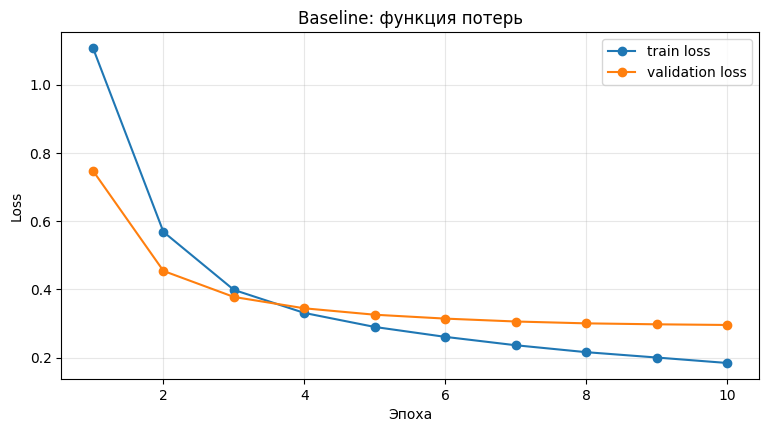

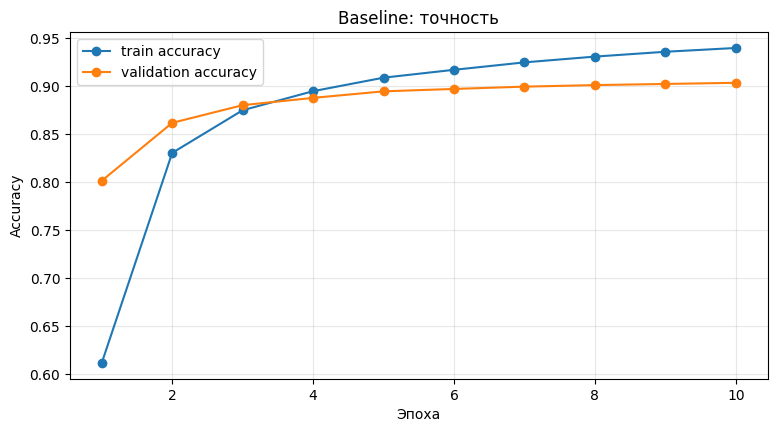

In [30]:
# Строим графики истории эксперимента.
def plot_history(metrics: pd.DataFrame, title: str = "Эксперимент") -> None:
    """Строит train/validation loss и accuracy для истории по эпохам."""
    history = metrics.groupby("epoch")[
        ["train_loss", "train_accuracy", "val_loss", "val_accuracy"]
    ].last()
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(history.index + 1, history["train_loss"], marker="o", label="train loss")
    ax.plot(history.index + 1, history["val_loss"], marker="o", label="validation loss")
    ax.set(xlabel="Эпоха", ylabel="Loss", title=f"{title}: функция потерь")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(
        history.index + 1, history["train_accuracy"], marker="o", label="train accuracy"
    )
    ax.plot(
        history.index + 1,
        history["val_accuracy"],
        marker="o",
        label="validation accuracy",
    )
    ax.set(xlabel="Эпоха", ylabel="Accuracy", title=f"{title}: точность")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()


plot_history(embedding_bag_metrics, "Baseline")

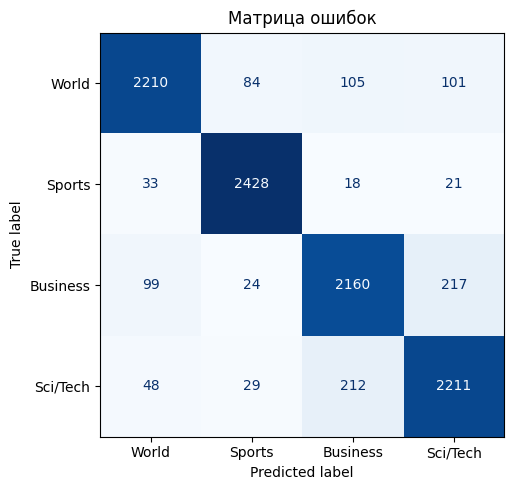

In [ ]:
# Получаем предсказанные классы и истинные метки для всей тестовой выборки.
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix


@torch.inference_mode()
def collect_predictions(
    model: nn.Module,
    loader: DataLoader,
    target_device: torch.device,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Возвращает истинные метки, предсказания и вероятности классов."""
    model.eval()

    all_targets: list[np.ndarray] = []
    all_predictions: list[np.ndarray] = []
    all_probabilities: list[np.ndarray] = []

    for data, labels in loader:
        # Переносим признаки на то же устройство, где расположена модель.
        if isinstance(data, (list, tuple)):
            data = [item.to(target_device) for item in data]
        else:
            data = data.to(target_device)

        # Модель возвращает логиты; Softmax преобразует их в вероятности для анализа.
        logits = model(*data)
        probabilities = torch.softmax(logits, dim=1)
        predictions = logits.argmax(dim=1)

        all_targets.append(labels.cpu().numpy())
        all_predictions.append(predictions.cpu().numpy())
        all_probabilities.append(probabilities.cpu().numpy())

    return (
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        np.concatenate(all_probabilities),
    )


def plot_matrix(model: nn.Module, loader: DataLoader):
    y_true, y_pred, _ = collect_predictions(model, loader, device)

    confusion = confusion_matrix(y_true, y_pred, labels=list(range(4)))

    fig, ax = plt.subplots(figsize=(5.25, 5))
    confusion_display = ConfusionMatrixDisplay(
        confusion_matrix=confusion,
        display_labels=CLASS_NAMES,
    )
    confusion_display.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title("Матрица ошибок")
    plt.tight_layout()
    plt.show()


plot_matrix(embedding_bag_best_model, test_embedding_loader)

### Почему baseline не учитывает порядок слов

Для усреднения embedding перестановка токенов не меняет результат: сумма тех же векторов остаётся прежней. Это свойство можно проверить численно на одном тексте.

Модель всё ещё может успешно классифицировать документы: в новостных темах часто встречаются характерные слова. Но она теряет информацию о локальном контексте и отношениях между словами. Именно этот недостаток мотивирует переход к последовательной обработке.

In [34]:
# Проверяем инвариантность среднего embedding к перестановке токенов одного документа.
baseline.eval()
first_sequence = train_dataset[0][0]
reversed_sequence = first_sequence.flip(0)
combined_tokens = torch.cat([first_sequence, reversed_sequence]).to(device)
combined_offsets = torch.tensor(
    [0, first_sequence.numel()], dtype=torch.long, device=device
)

with torch.inference_mode():
    original_logits = baseline(combined_tokens, combined_offsets)[0]
    reversed_logits = baseline(combined_tokens, combined_offsets)[1]

print(
    "Максимальное отличие логитов после разворота:",
    (original_logits - reversed_logits).abs().max().item(),
)

Максимальное отличие логитов после разворота: 1.4901161193847656e-08


**Небольшое исследование.** Почему несмотря на то, что baseline не учитывает порядок слов, для выбранного датасета она показывает себя хорошо? 

## Рекуррентная нейронная сеть: идея скрытого состояния

Рекуррентная нейронная сеть (Recurrent Neural Network, RNN) обрабатывает последовательность по одному элементу за шаг. На каждом шаге она получает embedding текущего токена и скрытое состояние предыдущего шага.

$$
\mathbf{h}_t = \tanh(W_{xh}\mathbf{x}_t + W_{hh}\mathbf{h}_{t-1}+\mathbf{b}_h).
$$

Здесь:

- $\mathbf{x}_t$ - embedding токена на позиции $t$;
- $\mathbf{h}_{t-1}$ - информация, накопленная к предыдущему шагу;
- $W_{xh}$ и $W_{hh}$ - обучаемые матрицы, которые **повторно используются на каждом шаге**;
- $\mathbf{h}_t$ - новое скрытое состояние.

В отличие от обычной полносвязной сети, здесь вход на текущем шаге зависит не только от текущего токена, но и от состояния, сформированного предыдущими токенами. Скрытое состояние играет роль краткого внутреннего представления уже прочитанной части последовательности.

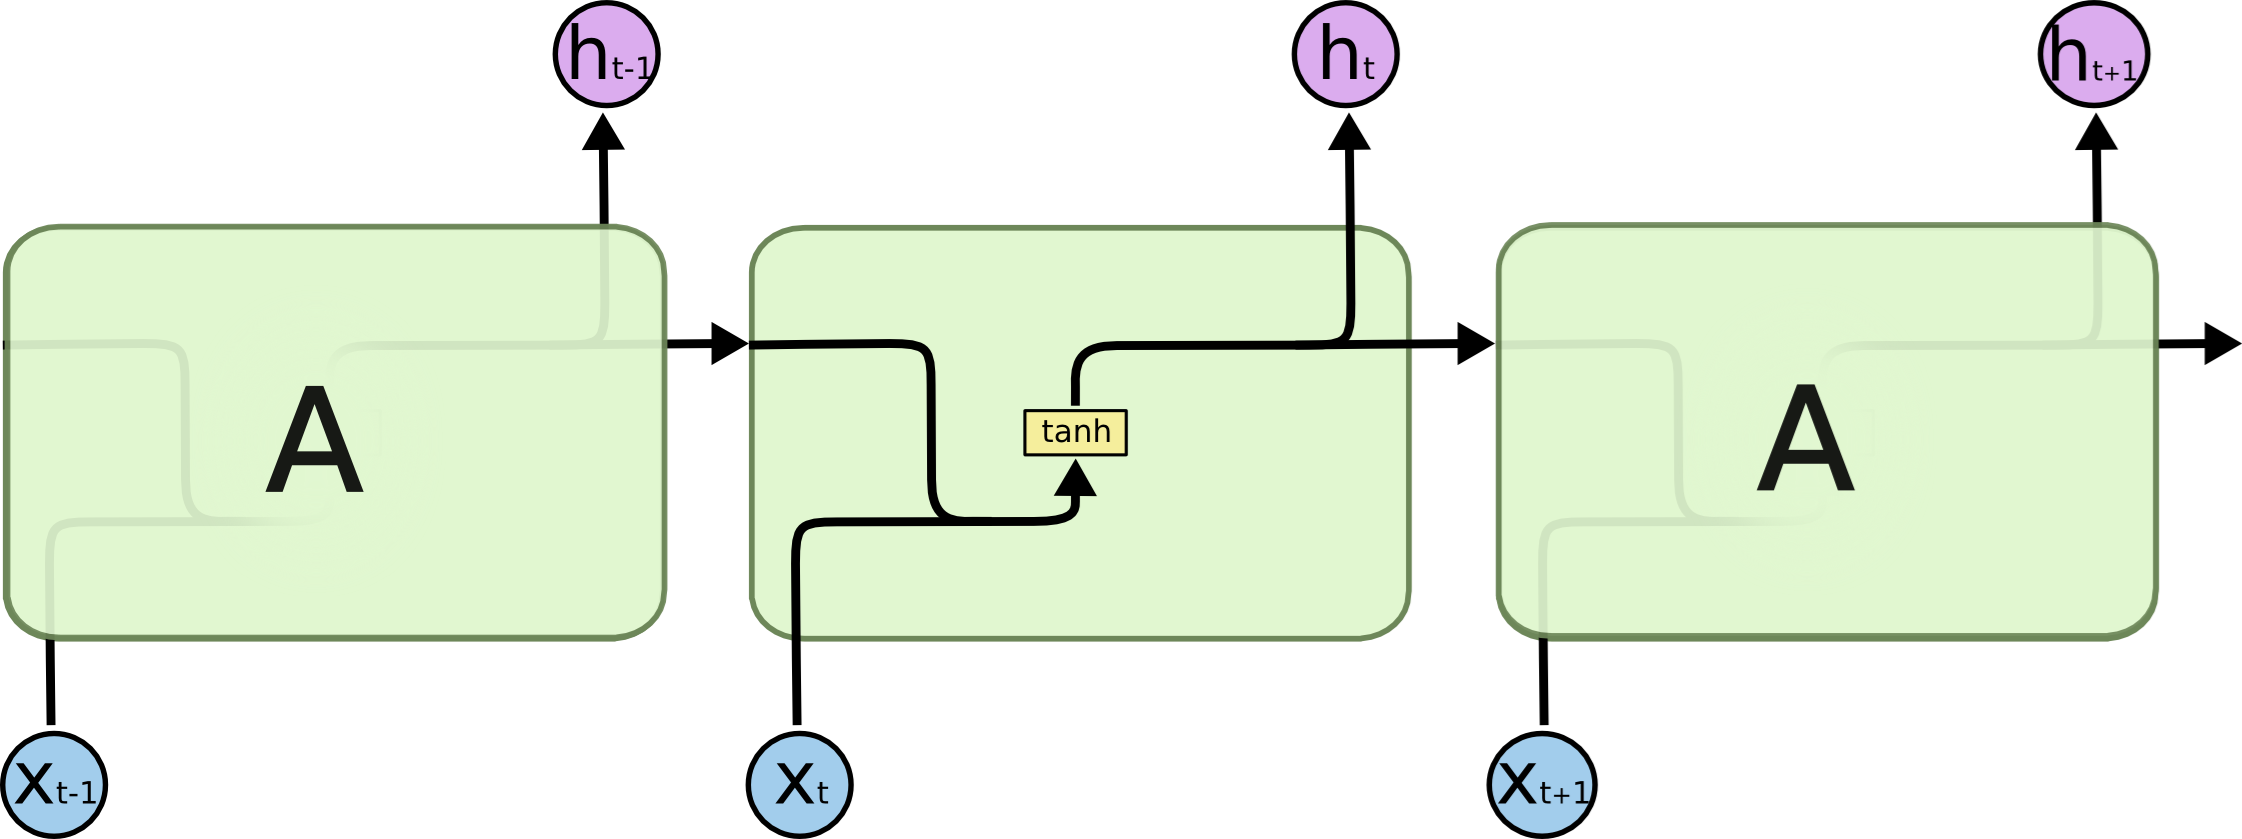

### Разворачивание RNN по шагам

Одна и та же рекуррентная ячейка применяется последовательно:

$$
\mathbf{h}_0\rightarrow(\mathbf{x}_1,\mathbf{h}_0)\rightarrow\mathbf{h}_1
\rightarrow(\mathbf{x}_2,\mathbf{h}_1)\rightarrow\mathbf{h}_2\rightarrow\cdots
\rightarrow\mathbf{h}_T.
$$

Для классификации целого документа можно использовать последнее скрытое состояние $\mathbf{h}_T$, а затем подать его в линейный классификатор:

$$
\mathbf{o}=W_c\mathbf{h}_T+\mathbf{b}_c.
$$

RNN не создаёт отдельные матрицы весов для каждой позиции. Одна и та же ячейка применяется ко всем токенам. Поэтому модель может обрабатывать последовательности разной длины.

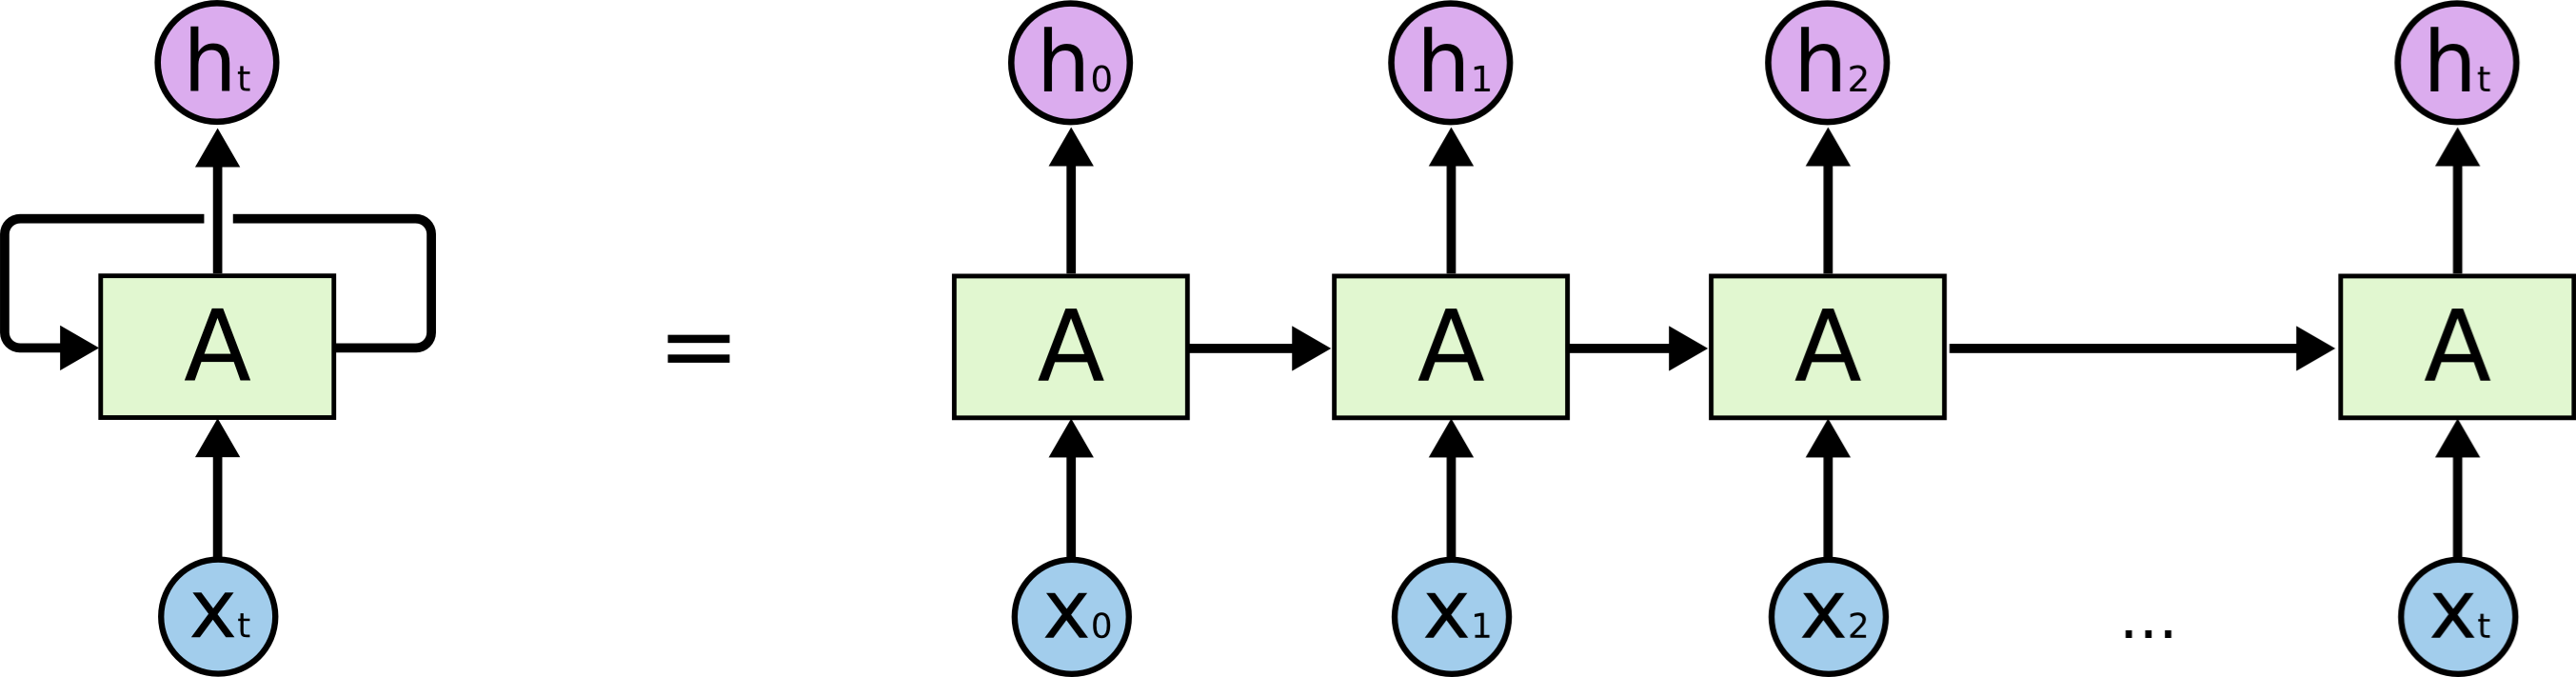

### Многослойная RNN

Многослойная RNN (Stacked RNN) состоит из нескольких рекуррентных слоёв, расположенных друг над другом. Каждый слой обрабатывает последовательность скрытых состояний предыдущего слоя и формирует собственную последовательность представлений.

Для двухслойной RNN вычисления можно записать следующим образом:

$$
\mathbf{h}_t^{(1)}
=
\tanh\left(
W_{xh}^{(1)}\mathbf{x}_t
+
W_{hh}^{(1)}\mathbf{h}_{t-1}^{(1)}
+
\mathbf{b}_h^{(1)}
\right),
$$

$$
\mathbf{h}_t^{(2)}
=
\tanh\left(
W_{xh}^{(2)}\mathbf{h}_t^{(1)}
+
W_{hh}^{(2)}\mathbf{h}_{t-1}^{(2)}
+
\mathbf{b}_h^{(2)}
\right).
$$

Здесь:

- $\mathbf{h}_t^{(1)}$ - скрытое состояние первого слоя на шаге $t$;
- $\mathbf{h}_t^{(2)}$ - скрытое состояние второго слоя на шаге $t$;
- каждый последующий слой получает на вход скрытое состояние предыдущего слоя;
- каждый слой имеет собственные обучаемые матрицы весов.

При этом между слоями можно в качестве дополнительной регуляризации добавлять Dropout.

Таким образом, первый слой формирует последовательность базовых представлений, а следующие слои преобразуют их, позволяя модели извлекать более сложные закономерности в последовательности.

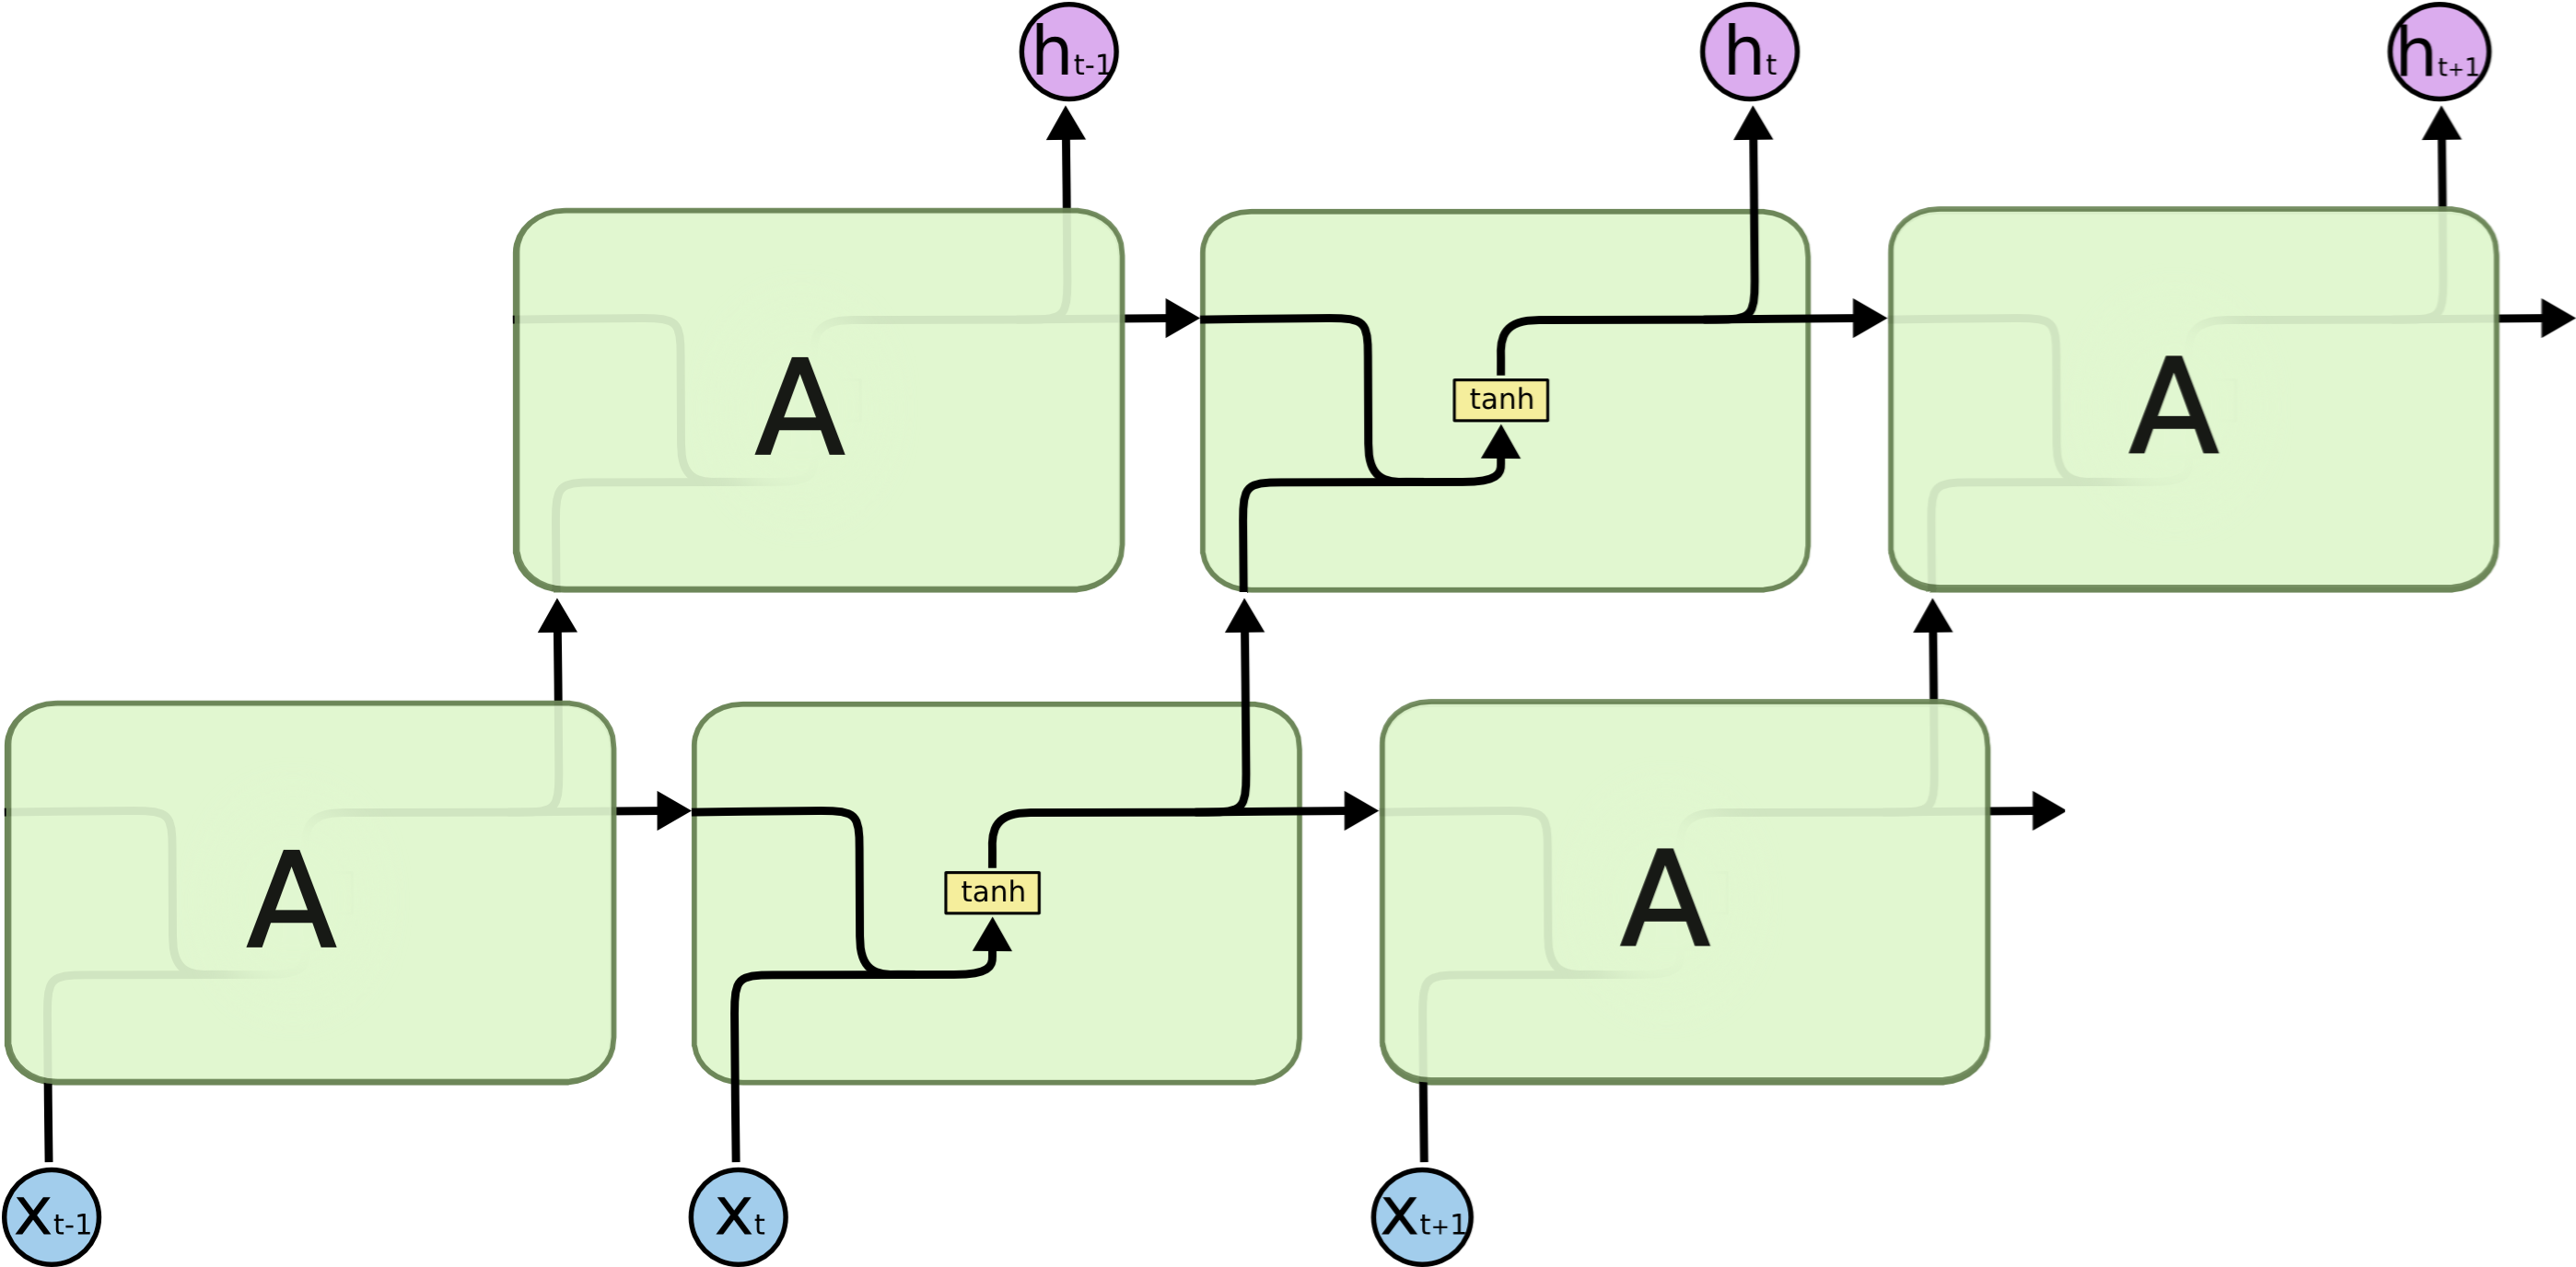

### Двунаправленная RNN (Bidirectional RNN)

Обычная RNN обрабатывает последовательность только слева направо: при вычислении состояния на позиции $t$ она использует текущий токен и информацию о предыдущих токенах.

Однако в некоторых задачах для понимания текущего токена важен не только предшествующий, но и последующий контекст. Например, смысл слова может зависеть от слов, которые стоят после него.

Двунаправленная RNN решает эту проблему с помощью двух независимых рекуррентных сетей:

- **прямая RNN** читает последовательность от первого токена к последнему;
- **обратная RNN** читает последовательность от последнего токена к первому.

Их скрытые состояния можно записать следующим образом:

$$
\overrightarrow{\mathbf{h}}_t
=
\tanh\left(
W_{xh}^{(f)}\mathbf{x}_t
+
W_{hh}^{(f)}\overrightarrow{\mathbf{h}}_{t-1}
+
\mathbf{b}_h^{(f)}
\right),
$$

$$
\overleftarrow{\mathbf{h}}_t
=
\tanh\left(
W_{xh}^{(b)}\mathbf{x}_t
+
W_{hh}^{(b)}\overleftarrow{\mathbf{h}}_{t+1}
+
\mathbf{b}_h^{(b)}
\right).
$$

На каждой позиции два полученных скрытых состояния объединяются, обычно с помощью конкатенации:

$$
\mathbf{h}_t
=
\left[
\overrightarrow{\mathbf{h}}_t
\,;\,
\overleftarrow{\mathbf{h}}_t
\right].
$$

В результате представление каждого токена содержит информацию как о предыдущем, так и о последующем контексте.

Для классификации целого документа можно объединить последние состояния обоих направлений:

$$
\mathbf{h}
=
\left[
\overrightarrow{\mathbf{h}}_T
\,;\,
\overleftarrow{\mathbf{h}}_1
\right],
$$

а затем подать полученное представление в линейный классификатор:

$$
\mathbf{o}
=
W_c\mathbf{h}
+
\mathbf{b}_c.
$$

Многослойность и двунаправленность можно сочетать: в этом случае каждый слой содержит два направления обработки, а его выход передаётся следующему слою.

**Важно:** двунаправленная RNN использует информацию из всей последовательности, поэтому подходит для задач классификации текста, где последовательность целиком доступна заранее. Для генерации текста в режиме реального времени такой подход обычно не подходит, поскольку обратное направление использует информацию из будущих токенов.


### Тензорные формы в рекуррентной модели

При использовании `batch_first=True` вход RNN имеет форму `[B, T, E]`:

- `B` - размер батча;
- `T` - длина последовательности после padding;
- `E` - размерность embedding.

Если `hidden_size=H`, то для однонаправленной однослойной RNN последнее скрытое состояние имеет форму `[1, B, H]`. Для двунаправленной - `[2, B, H]`.

После объединения направлений представление документа имеет размерность `[B, 2H]`. Если сеть однонаправленная, размерность будет `[B, H]`.

In [37]:
# Создаём компактную RNN и вручную прослеживаем формы выходной последовательности и hidden state.
shape_embedding = nn.Embedding(
    num_embeddings=len(vocab),
    embedding_dim=128,
    padding_idx=vocab.pad_idx,
).to(device)

shape_rnn = nn.RNN(
    input_size=128,
    hidden_size=128,
    num_layers=2,
    batch_first=True,
    bidirectional=True,
).to(device)

sample_tokens = sequence_tokens[:4].to(device)
sample_embeddings = shape_embedding(sample_tokens)
rnn_outputs, rnn_hidden = shape_rnn(sample_embeddings)

print("Token indices:", tuple(sample_tokens.shape))
print("Embeddings:", tuple(sample_embeddings.shape))
print("RNN outputs:", tuple(rnn_outputs.shape))
print("RNN hidden:", tuple(rnn_hidden.shape))

Token indices: (4, 89)
Embeddings: (4, 89, 128)
RNN outputs: (4, 89, 256)
RNN hidden: (4, 4, 128)


## Классификатор на `nn.RNN`

Реализуем сеть, которая кодирует текст последовательностью скрытых состояний. Чтобы получить представление документа, возьмём последнее состояние каждого направления.

Для одно- и двунаправленной сети форма `hidden` различается. Удобно привести её к виду:

$$
[\text{num\_layers},\text{num\_directions},B,H]
$$

и выбрать последний слой. Затем направления объединяются по последней оси.

В коде также используем `pack_padded_sequence`: он сообщает рекуррентной сети реальные длины текстов, поэтому padding не участвует в рекуррентных вычислениях.

In [86]:
# Реализуем RNN-классификатор с embedding, упаковкой последовательностей и итоговым скрытым состоянием.
class RNNTextClassifier(nn.Module):
    """Классификатор AG News на обычной рекуррентной нейронной сети."""

    def __init__(
        self,
        vocab_size: int,
        num_classes: int,
        pad_idx: int,
        embedding_dim: int = 128,
        hidden_size: int = 128,
        num_layers: int = 2,
        dropout: float = 0.3,
        bidirectional: bool = True,
    ) -> None:
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.num_directions = 2 if bidirectional else 1

        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)

        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=(
                dropout if num_layers > 1 else 0.0
            ),  # Дополнительно применяем dropout при передаче состояния между рекуррентными слоями.
            nonlinearity="tanh",
        )

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size * self.num_directions, num_classes)

    def forward(self, tokens: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        # Получаем вектор каждого токена: [B, T] -> [B, T, E].
        embedded = self.embedding(tokens)

        # Длины должны быть на CPU; enforce_sorted=False разрешает произвольный порядок примеров.
        packed = pack_padded_sequence(
            embedded,
            lengths.detach().cpu(),
            batch_first=True,
            enforce_sorted=False,
        )
        _, hidden = self.rnn(packed)

        # Приводим hidden к [num_layers, directions, B, H] и выбираем последний слой.
        hidden = hidden.view(
            self.num_layers,
            self.num_directions,
            tokens.size(0),
            self.hidden_size,
        )
        last_layer = hidden[-1]
        document_vector = last_layer.transpose(0, 1).reshape(tokens.size(0), -1)

        return self.classifier(self.dropout(document_vector))

In [87]:
# Проверяем RNNTextClassifier на реальном батче и рассчитываем число параметров.
rnn_model = RNNTextClassifier(
    vocab_size=len(vocab),
    num_classes=len(CLASS_NAMES),
    pad_idx=vocab.pad_idx,
    bidirectional=True,
).to(device)

with torch.no_grad():
    rnn_demo_logits = rnn_model(
        sequence_tokens[:8].to(device),
        sequence_lengths[:8],
    )

rnn_parameter_count = sum(p.numel() for p in rnn_model.parameters() if p.requires_grad)
print("Логиты:", tuple(rnn_demo_logits.shape))
print("Число параметров:", f"{rnn_parameter_count:,}")

Логиты: (8, 4)
Число параметров: 3,837,060


## Padding и `pack_padded_sequence`

Padding нужен, чтобы сложить последовательности в матрицу `[B, T]`, но искусственные `<PAD>` не должны влиять на итоговое представление текста.

Можно передать padded-тензор напрямую в RNN и попытаться взять последнее состояние. Однако сеть продолжит обновлять скрытое состояние и на позициях padding. Если реальная длина примера меньше максимальной длины батча, финальное состояние окажется связано с обработкой искусственных токенов.

`pack_padded_sequence` создаёт специальное представление, которое содержит только действительные шаги последовательностей. Рекуррентная сеть пропускает вычисления на padded-позициях.

Поскольку в нашем collator примеры не сортируются по длине, задаём `enforce_sorted=False`. Длины передаём на CPU - это требование операции упаковки.

In [88]:
# Показываем, сколько реальных временных шагов остаётся в PackedSequence после удаления padding.
example_tokens = sequence_tokens[:4].to(device)
example_lengths = sequence_lengths[:4]
example_embeddings = shape_embedding(example_tokens)
example_packed = pack_padded_sequence(
    example_embeddings,
    example_lengths.cpu(),
    batch_first=True,
    enforce_sorted=False,
)

print("Padded embeddings:", tuple(example_embeddings.shape))
print("Packed data:", tuple(example_packed.data.shape))
print("Batch sizes по временным шагам:", example_packed.batch_sizes.tolist())
print("Элементов с padding:", example_embeddings.size(0) * example_embeddings.size(1))
print("Реальных токенов:", int(example_lengths.sum()))

Padded embeddings: (4, 89, 128)
Packed data: (166, 128)
Batch sizes по временным шагам: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 1]
Элементов с padding: 356
Реальных токенов: 166


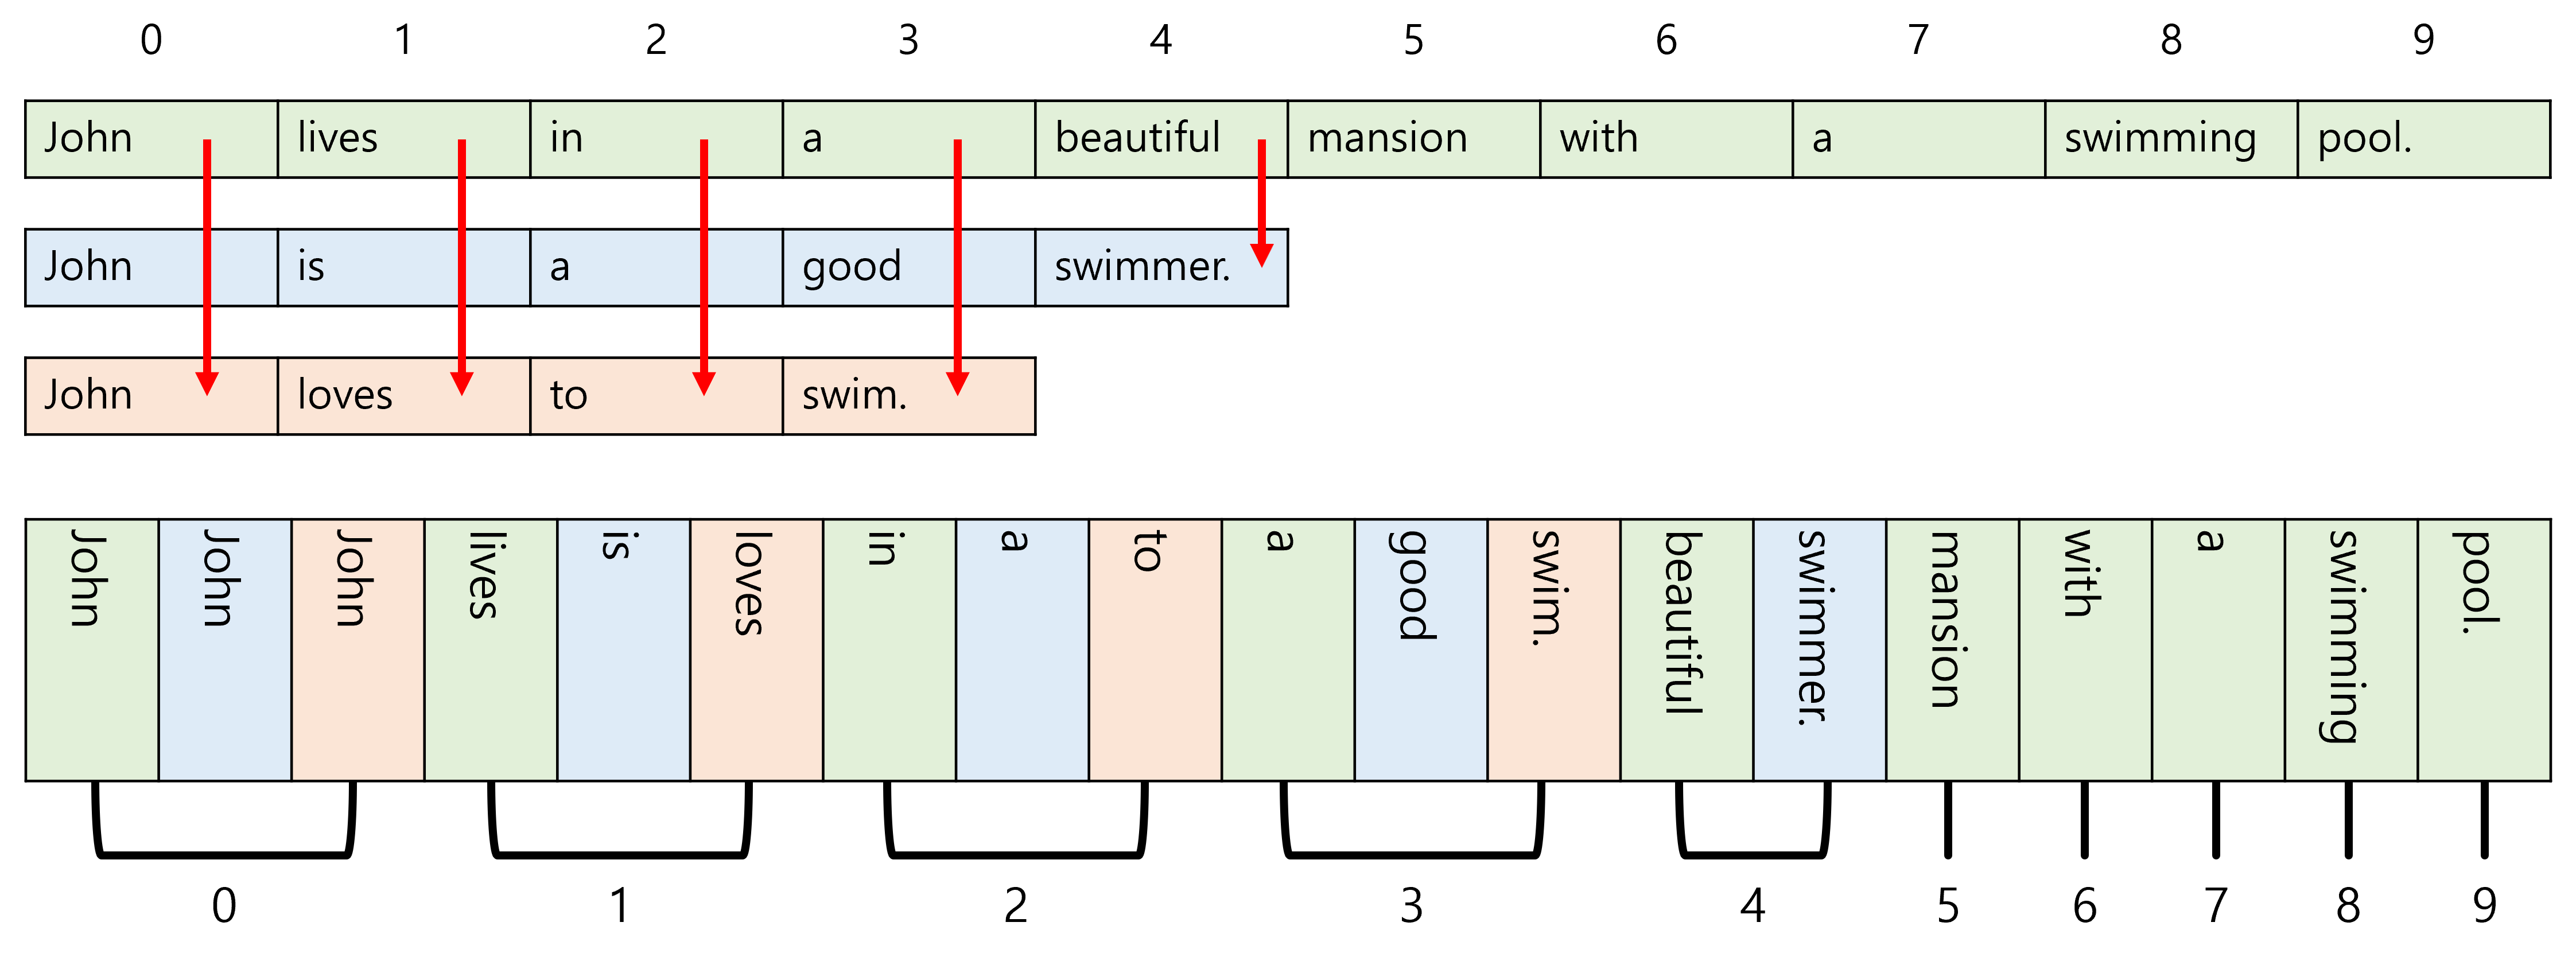

### Обратное преобразование: `pad_packed_sequence`

Если после рекуррентного слоя нужно получить все скрытые состояния в обычном тензоре, можно вызвать `pad_packed_sequence`. Он восстановит форму `[B, T, H]` и вернёт длины.

Для классификатора целого документа все состояния нам не обязательны - достаточно итогового hidden state. Но в задачах sequence labeling, например разметки каждого токена, последовательность выходов может понадобиться.

In [89]:
# Восстанавливаем padded-последовательность из PackedSequence и проверяем итоговые формы.
packed_outputs, packed_hidden = shape_rnn(example_packed)
restored_outputs, restored_lengths = pad_packed_sequence(
    packed_outputs,
    batch_first=True,
    padding_value=0.0,
)
print("Выход после unpack:", tuple(restored_outputs.shape))
print("Восстановленные длины:", restored_lengths.tolist())

Выход после unpack: (4, 47, 256)
Восстановленные длины: [44, 29, 46, 47]


### Обучение RNN
Воспользуемся описанным выше `TextClassifierLitModel`

In [ ]:
# Обучаем rnn.
rnn_lit = TextClassifierLitModel(
    model=RNNTextClassifier,
    vocab_size=len(vocab),
    num_classes=len(CLASS_NAMES),
    pad_idx=vocab.pad_idx,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    seed=SEED,
)

rnn_metrics = rnn_lit.fit(
    train_loader=train_sequence_loader,
    validation_loader=validation_sequence_loader,
    epochs=MAX_EPOCHS,
    patience=MAX_EPOCHS,
)

rnn_best_model = rnn_lit.to(device).model.eval()

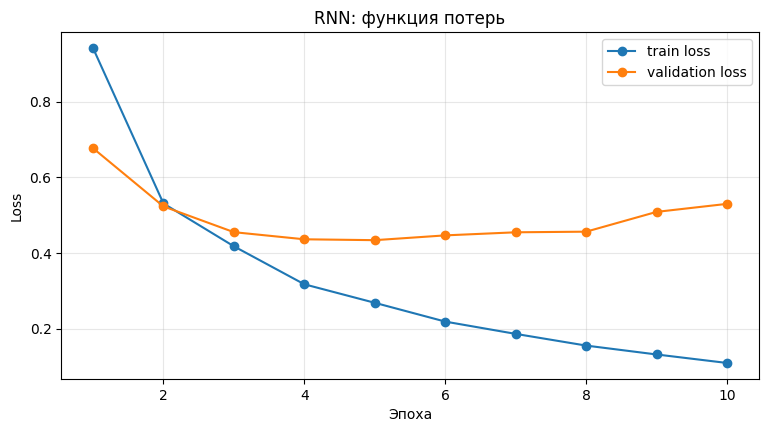

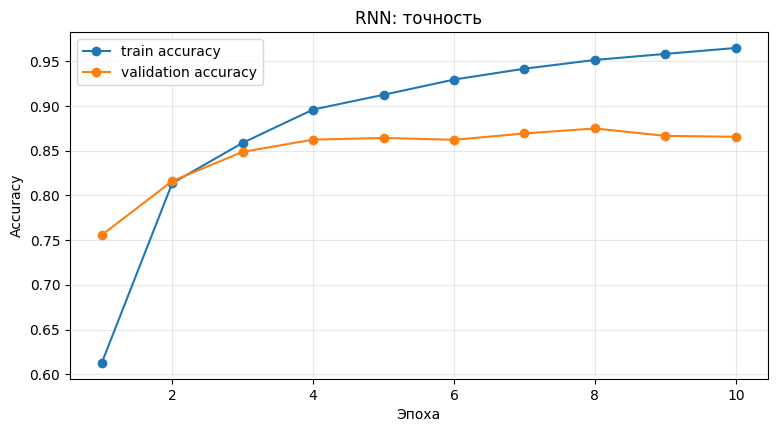

In [91]:
plot_history(rnn_metrics, "RNN")

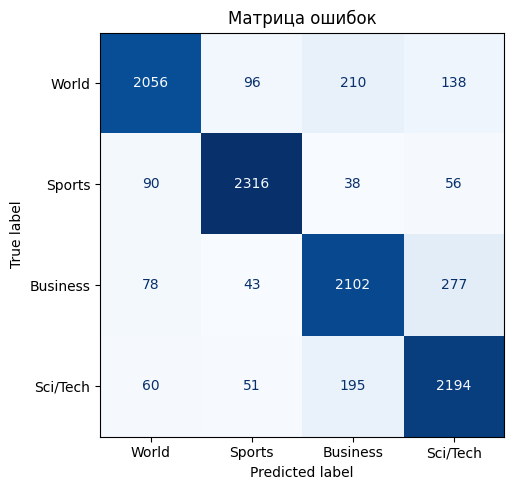

In [92]:
plot_matrix(rnn_best_model, test_sequence_loader)

**Небольшое исследование.** Сравните качество baseline модели и rnn. Какая модель показывает себя лучше? Как это может быть связано с выбранным датасетом?

## Backpropagation Through Time (BPTT)

Обычное обратное распространение ошибки применяется и к рекуррентным сетям. Разница заключается в том, что рекуррентная ячейка многократно используется на последовательных шагах. При обучении вычислительный граф разворачивается во времени, поэтому обратный проход должен пройти от последних шагов к предыдущим.

Этот подход называется **Backpropagation Through Time (BPTT)**.

Поскольку одно и то же преобразование применяется на каждом шаге, градиент по рекуррентным весам складывает вклад разных позиций последовательности. При этом градиент к ранним шагам проходит через цепочку производных:

$$
\frac{\partial\mathcal{L}}{\partial\mathbf{h}_t}
=\frac{\partial\mathcal{L}}{\partial\mathbf{h}_T}
\prod_{k=t+1}^{T}
\frac{\partial\mathbf{h}_k}{\partial\mathbf{h}_{k-1}}.
$$

Чем длиннее цепочка, тем больше возможностей для изменения масштаба градиента. Поэтому обучение на длинных зависимостях может быть затруднено.

### Проблемы оптимизации глубоких RNN

Из-за BPTT рекуррентная сеть при обучении фактически ведёт себя как глубокая сеть: вычислительный граф разворачивается по временным шагам, и градиент проходит через последовательность преобразований.

Поэтому для RNN актуальны те же проблемы оптимизации, что и для глубоких CNN (см. работу № 3):

- **Затухание градиента** - при прохождении через длинную цепочку производных норма градиента может уменьшаться. В результате ранние временные шаги получают слишком маленькие обновления, и сети становится трудно учитывать далёкие зависимости.
- **Взрыв градиента** - норма градиента может чрезмерно увеличиваться, что приводит к нестабильным обновлениям параметров и затрудняет обучение.

Таким образом, увеличение длины последовательности может усложнять оптимизацию RNN по тем же причинам, по которым увеличение глубины затрудняет обучение обычных нейронных сетей.

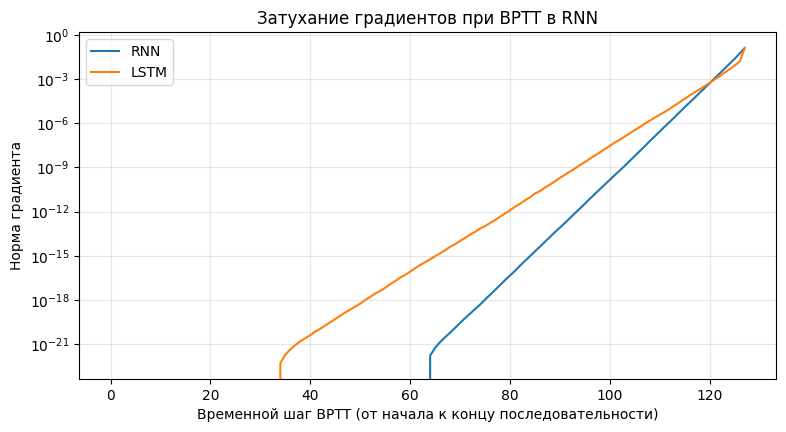

In [61]:
# Сравниваем нормы градиентов промежуточных активаций на каждом временном шаге BPTT.

import torch.nn.functional as F


class GradientRNN(nn.Module):
    def __init__(
        self, input_size: int = 128, hidden_size: int = 128, num_classes: int = 4
    ):
        super().__init__()

        self.input_layer = nn.Linear(input_size, hidden_size)
        self.hidden_layer = nn.Linear(hidden_size, hidden_size)
        self.classifier = nn.Linear(hidden_size, num_classes)

        self.activations = []

    def forward_with_activations(self, x: torch.Tensor):
        """Возвращает логиты и скрытые состояния на каждом шаге."""

        batch_size, sequence_length, _ = x.shape

        h = torch.zeros(batch_size, self.hidden_layer.out_features, device=x.device)

        self.activations = []

        for t in range(sequence_length):
            h = F.tanh(self.input_layer(x[:, t, :]) + self.hidden_layer(h))

            # Сохраняем градиенты скрытых состояний
            h.retain_grad()
            self.activations.append(h)

        logits = self.classifier(h)

        return logits


class GradientLSTM(nn.Module):
    def __init__(
        self, input_size: int = 128, hidden_size: int = 128, num_classes: int = 4
    ):
        super().__init__()

        self.hidden_size = hidden_size

        self.lstm = nn.LSTM(
            input_size=input_size, hidden_size=hidden_size, batch_first=True
        )

        self.classifier = nn.Linear(hidden_size, num_classes)

        self.activations = []

    def forward_with_activations(self, x: torch.Tensor):
        """Возвращает логиты и скрытые состояния h на каждом шаге."""

        batch_size, sequence_length, _ = x.shape

        h = torch.zeros(1, batch_size, self.hidden_size, device=x.device)
        c = torch.zeros(1, batch_size, self.hidden_size, device=x.device)

        self.activations = []

        for t in range(sequence_length):
            output, (h, c) = self.lstm(x[:, t : t + 1, :], (h, c))

            # Сохраняем градиенты только скрытых состояний h_t
            h.retain_grad()
            self.activations.append(h)

        logits = self.classifier(h.squeeze(0))

        return logits


gradient_batch = torch.randn(16, 128, 128, device=device)
gradient_targets = torch.randint(0, 4, (16,), device=device)
gradient_criterion = nn.CrossEntropyLoss()

gradient_models = {
    "RNN": GradientRNN().to(device),
    "LSTM": GradientLSTM().to(device),
}

gradient_norms = {}

for model_name, model in gradient_models.items():
    model.train()
    model.zero_grad(set_to_none=True)

    logits = model.forward_with_activations(gradient_batch)

    loss = gradient_criterion(logits, gradient_targets)
    loss.backward()

    # Вычисляем норму градиента каждого скрытого состояния
    gradient_norms[model_name] = [
        activation.grad.norm().item() for activation in model.activations
    ]


depth_positions = np.arange(len(next(iter(gradient_norms.values()))))

plt.figure(figsize=(9, 4.5))

for model_name, norms in gradient_norms.items():
    plt.plot(depth_positions, norms, label=model_name)

plt.xlabel("Временной шаг BPTT (от начала к концу последовательности)")
plt.ylabel("Норма градиента")
plt.title("Затухание градиентов при BPTT в RNN")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## LSTM: ячейка с управляемой памятью

Long Short-Term Memory (LSTM) расширяет обычную RNN отдельным состоянием ячейки $\mathbf{c}_t$. Внутри используются управляющие **ворота** (*gates*), которые определяют, какую информацию сохранить, добавить или передать дальше.

Основные компоненты:

- **forget gate** $\mathbf{f}_t$ определяет, какую часть предыдущего состояния ячейки сохранить;
- **input gate** $\mathbf{i}_t$ регулирует запись новой информации;
- **candidate** $\tilde{\mathbf{c}}_t$ предлагает новое содержимое памяти;
- **output gate** $\mathbf{o}_t$ определяет, какая часть состояния ячейки станет скрытым состоянием.

Упрощённая запись уравнений:

$$
\begin{aligned}
\mathbf{f}_t &= \sigma(W_f[\mathbf{x}_t,\mathbf{h}_{t-1}]+\mathbf{b}_f),\\
\mathbf{i}_t &= \sigma(W_i[\mathbf{x}_t,\mathbf{h}_{t-1}]+\mathbf{b}_i),\\
\tilde{\mathbf{c}}_t &= \tanh(W_c[\mathbf{x}_t,\mathbf{h}_{t-1}]+\mathbf{b}_c),\\
\mathbf{c}_t &= \mathbf{f}_t\odot\mathbf{c}_{t-1}+\mathbf{i}_t\odot\tilde{\mathbf{c}}_t,\\
\mathbf{o}_t &= \sigma(W_o[\mathbf{x}_t,\mathbf{h}_{t-1}]+\mathbf{b}_o),\\
\mathbf{h}_t &= \mathbf{o}_t\odot\tanh(\mathbf{c}_t).
\end{aligned}
$$

Здесь $\odot$ - поэлементное умножение. Состояние ячейки позволяет создавать более прямой путь переноса информации между шагами. Это помогает обучать зависимости, которые обычной RNN сохранять трудно, хотя не гарантирует идеальную память на произвольной длине.

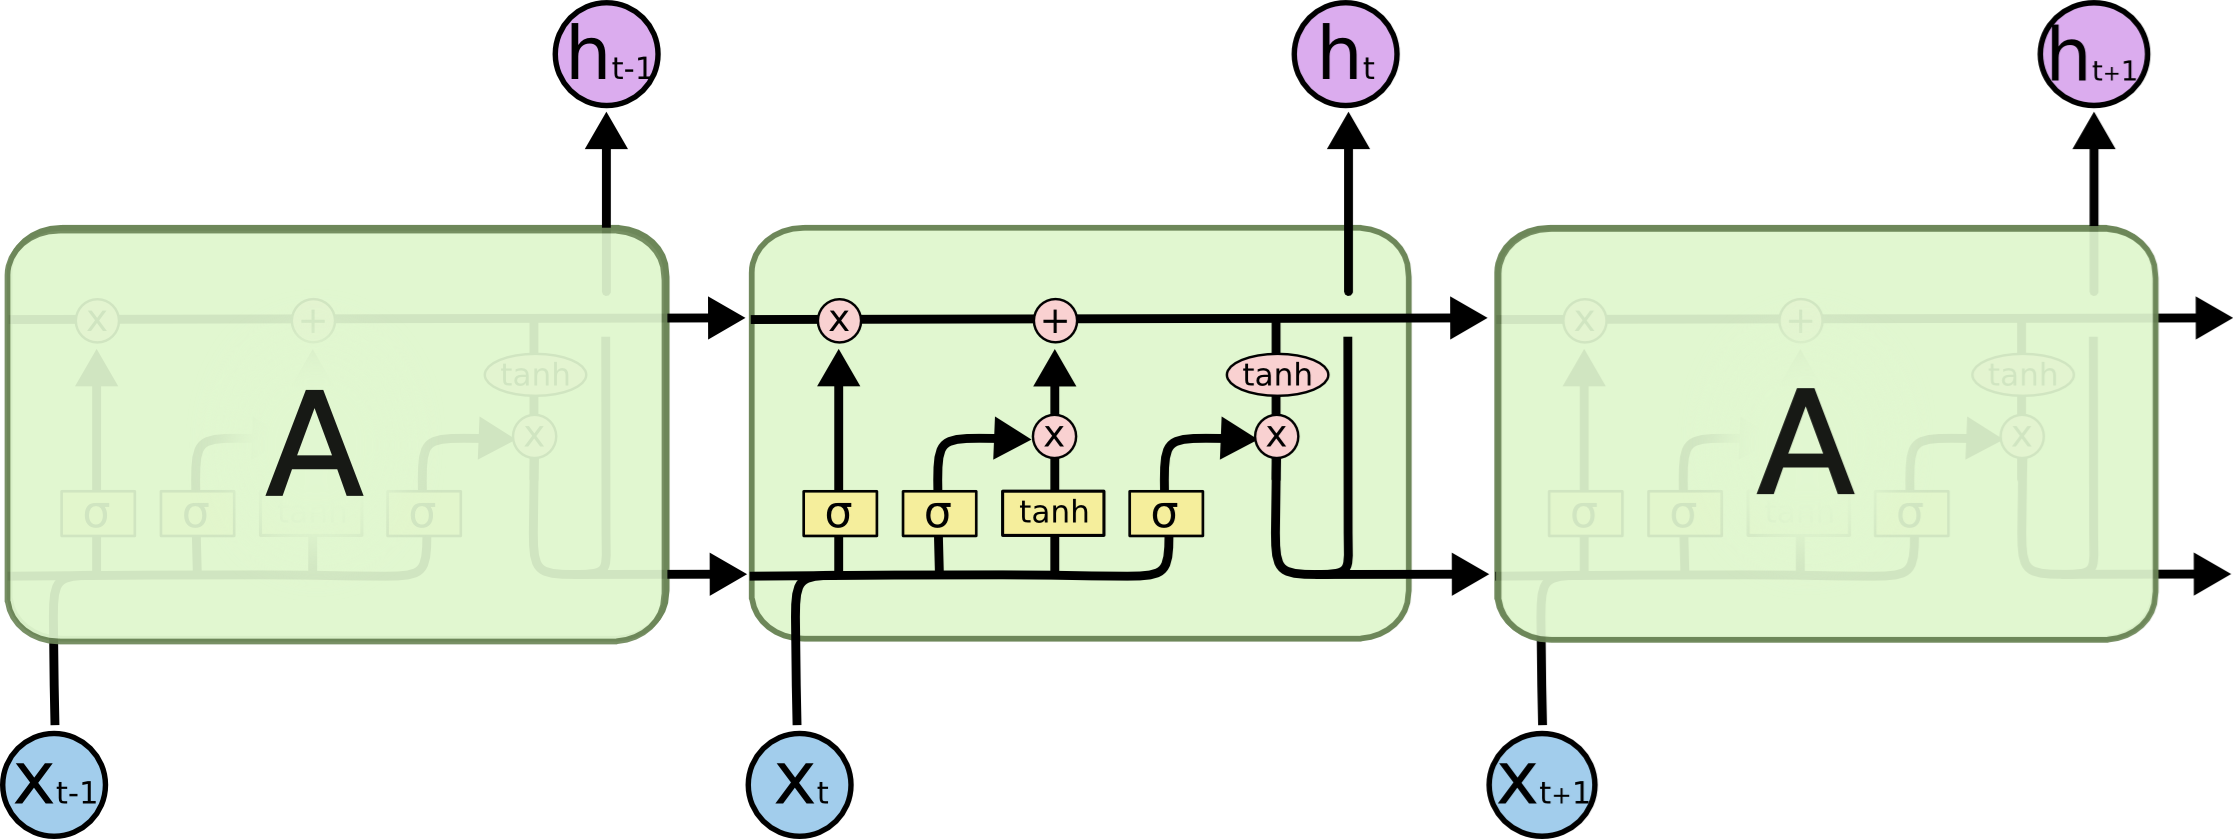

### Как PyTorch возвращает состояния LSTM

У `nn.LSTM` результат отличается от `nn.RNN` и `nn.GRU`:

```python
output, (h_n, c_n) = lstm(input)
```

- `output` содержит выходы на временных шагах;
- `h_n` - итоговые скрытые состояния;
- `c_n` - итоговые состояния ячеек.

Для классификации документа обычно используют `h_n`. Если сеть двунаправленная, нужно взять состояния последнего слоя для обоих направлений и объединить их. `c_n` важен для внутренней работы LSTM, но в простом классификаторе не подаётся непосредственно в линейную голову.

## GRU: более компактная gated-архитектура

Gated Recurrent Unit (GRU) также использует управляющие ворота, но объединяет некоторые механизмы LSTM и не поддерживает отдельное состояние ячейки $\mathbf{c}_t$. Основные ворота:

- **update gate** $\mathbf{z}_t$ управляет тем, сколько предыдущего состояния перенести дальше;
- **reset gate** $\mathbf{r}_t$ определяет, насколько учитывать предыдущее состояние при построении кандидата.

Одна из распространённых форм записи:

$$
\begin{aligned}
\mathbf{z}_t &= \sigma(W_z[\mathbf{x}_t,\mathbf{h}_{t-1}]),\\
\mathbf{r}_t &= \sigma(W_r[\mathbf{x}_t,\mathbf{h}_{t-1}]),\\
\tilde{\mathbf{h}}_t &= \tanh(W_h[\mathbf{x}_t,\mathbf{r}_t\odot\mathbf{h}_{t-1}]),\\
\mathbf{h}_t &= \mathbf{z}_t\odot\mathbf{h}_{t-1}+(1-\mathbf{z}_t)\odot\tilde{\mathbf{h}}_t.
\end{aligned}
$$

GRU часто имеет меньше параметров, чем сопоставимая LSTM, поскольку использует меньше управляющих преобразований. Однако нельзя заранее утверждать, что GRU всегда быстрее или точнее: результат зависит от размера модели, данных, реализации и оборудования.

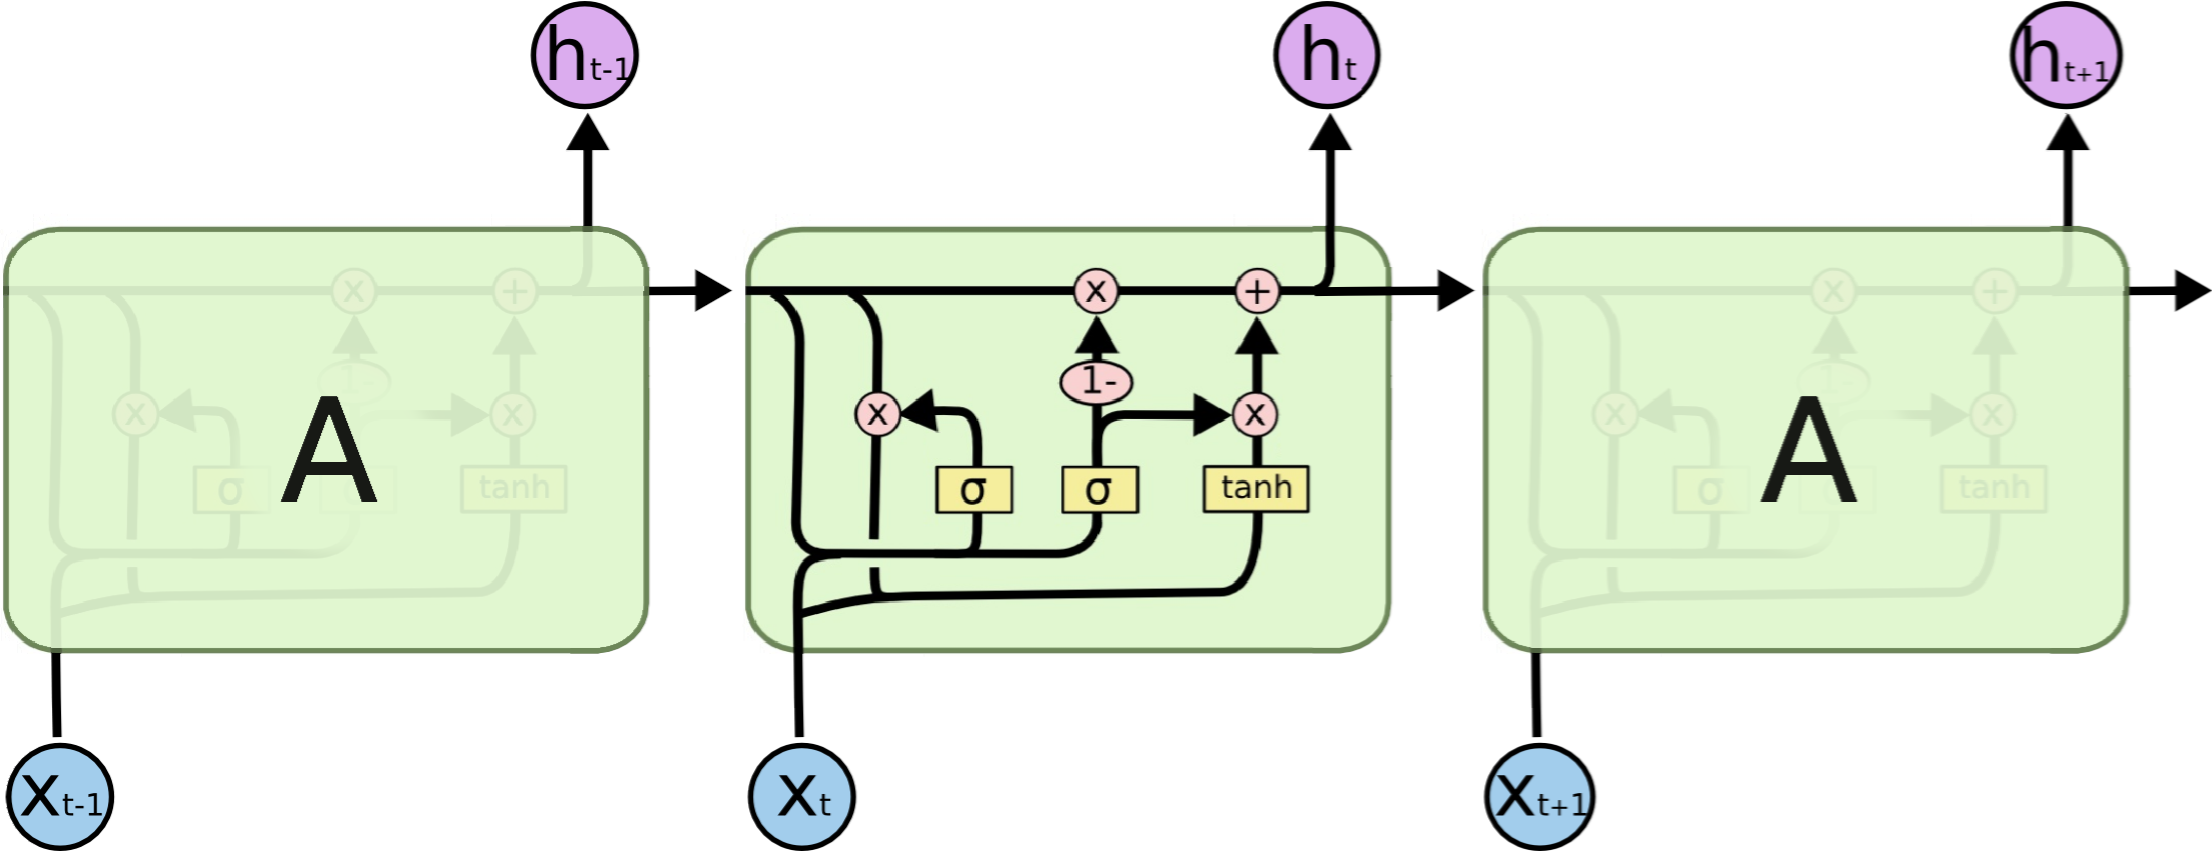

### Сравнение RNN, LSTM и GRU

| Архитектура | Состояние | Механизм | Особенности |
|---|---|---|---|
| RNN | $h_t$ | Простое рекуррентное обновление | Компактна, но хуже удерживает далёкие зависимости |
| LSTM | $h_t, c_t$ | Forget, input и output gates | Отдельное состояние памяти и более сложное управление информацией |
| GRU | $h_t$ | Update и reset gates | Более компактная gated-архитектура без отдельного cell state |

Все три архитектуры в этой работе получают одинаковые embedding, используют одинаковое разбиение данных и решают одну задачу. Это позволит сравнить их при контролируемых условиях.

## Реализация LSTM-классификатора

Теперь заменим обычную рекуррентную ячейку на LSTM. Вход, embedding, упаковка последовательностей и классификационная голова останутся такими же. Основное изменение - тип рекуррентного слоя и способ получения итогового скрытого состояния.

1. Создайте `nn.LSTM` с теми же параметрами, что использовались у `nn.RNN`.
2. Выполните прямой проход для `PackedSequence` и получите `hidden` и `cell`.
3. Приведите `hidden` к форме `[num_layers, directions, B, hidden_size]` и извлеките последний слой.
4. Объедините направления и примените классификатор.

In [ ]:
# Каркас LSTM-классификатора: сохраните общий интерфейс RNNTextClassifier.
class LSTMTextClassifier(nn.Module):
    """Классификатор AG News на LSTM."""

    def __init__(
        self,
        vocab_size: int,
        num_classes: int,
        pad_idx: int,
        embedding_dim: int = 128,
        hidden_size: int = 128,
        num_layers: int = 2,
        dropout: float = 0.3,
        bidirectional: bool = True,
    ) -> None:
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.num_directions = 2 if bidirectional else 1

        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)

        # Создайте nn.LSTM с input_size, hidden_size, num_layers,
        # batch_first=True, bidirectional=bidirectional и dropout при num_layers > 1.
        self.lstm = ...

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size * self.num_directions, num_classes)

    def forward(self, tokens: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        embedded = self.embedding(tokens)
        packed = pack_padded_sequence(
            embedded,
            lengths.detach().to("cpu"),
            batch_first=True,
            enforce_sorted=False,
        )

        # Получите h_n и c_n из self.lstm(packed).
        # Для классификации используйте hidden; cell нужен самой LSTM для обновления памяти.
        _, (hidden, cell) = self.lstm(packed)

        # Приведите hidden к форме [num_layers, directions, B, hidden_size].
        # Затем выберите последний слой и объедините направления в [B, directions * hidden_size].
        hidden = ...
        last_layer = ...
        document_vector = ...

        return self.classifier(self.dropout(document_vector))

## Реализация GRU-классификатора

GRU использует только одно итоговое скрытое состояние. Поэтому в отличие от LSTM не нужно обрабатывать пару `(hidden, cell)`.

1. Создайте `nn.GRU` с теми же размерами и настройками.
2. Получите `hidden` из результата `self.gru(packed)`.
3. Преобразуйте его к форме `[num_layers, directions, B, hidden_size]`.
4. Выберите последнее состояние последнего слоя и объедините направления.

In [ ]:
# Каркас GRU-классификатора: заполните создание слоя и извлечение итогового hidden state.
class GRUTextClassifier(nn.Module):
    """Классификатор AG News на GRU."""

    def __init__(
        self,
        vocab_size: int,
        num_classes: int,
        pad_idx: int,
        embedding_dim: int = 128,
        hidden_size: int = 128,
        num_layers: int = 2,
        dropout: float = 0.3,
        bidirectional: bool = True,
    ) -> None:
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.num_directions = 2 if bidirectional else 1

        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)

        # Создайте nn.GRU с теми же параметрами, что и nn.RNN/nn.LSTM.
        self.gru = ...

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size * self.num_directions, num_classes)

    def forward(self, tokens: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        embedded = self.embedding(tokens)
        packed = pack_padded_sequence(
            embedded,
            lengths.detach().to("cpu"),
            batch_first=True,
            enforce_sorted=False,
        )

        # Получите hidden из self.gru(packed).
        _, hidden = self.gru(packed)

        # Преобразуйте hidden к форме [num_layers, directions, B, hidden_size],
        # выберите последний слой и объедините направления.
        hidden = ...
        last_layer = ...
        document_vector = ...

        return self.classifier(self.dropout(document_vector))

In [ ]:
# Проверка архитектур до обучения.

lstm_demo = LSTMTextClassifier(
    vocab_size=len(vocab),
    num_classes=len(CLASS_NAMES),
    pad_idx=vocab.pad_idx,
).to(device)
gru_demo = GRUTextClassifier(
    vocab_size=len(vocab),
    num_classes=len(CLASS_NAMES),
    pad_idx=vocab.pad_idx,
).to(device)

with torch.inference_mode():
    lstm_logits = lstm_demo(sequence_tokens[:8].to(device), sequence_lengths[:8])
    gru_logits = gru_demo(sequence_tokens[:8].to(device), sequence_lengths[:8])

print("LSTM:", tuple(lstm_logits.shape))
print("GRU:", tuple(gru_logits.shape))
assert lstm_logits.shape == gru_logits.shape == (8, len(CLASS_NAMES))

LSTM: (8, 4)
GRU: (8, 4)


## Обучение LSTM и GRU

После реализации моделей обучите их на с теми же настройками, что использовались для RNN.

In [ ]:
# Обучаем lstm.
lstm_lit = TextClassifierLitModel(
    model=LSTMTextClassifier,
    vocab_size=len(vocab),
    num_classes=len(CLASS_NAMES),
    pad_idx=vocab.pad_idx,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    seed=SEED,
)

lstm_metrics = lstm_lit.fit(
    train_loader=train_sequence_loader,
    validation_loader=validation_sequence_loader,
    epochs=MAX_EPOCHS,
    patience=MAX_EPOCHS,
)

lstm_best_model = lstm_lit.to(device).model.eval()

In [ ]:
# Обучаем gru.
gru_lit = TextClassifierLitModel(
    model=GRUTextClassifier,
    vocab_size=len(vocab),
    num_classes=len(CLASS_NAMES),
    pad_idx=vocab.pad_idx,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    seed=SEED,
)

gru_metrics = gru_lit.fit(
    train_loader=train_sequence_loader,
    validation_loader=validation_sequence_loader,
    epochs=MAX_EPOCHS,
    patience=MAX_EPOCHS,
)

gru_best_model = gru_lit.to(device).model.eval()

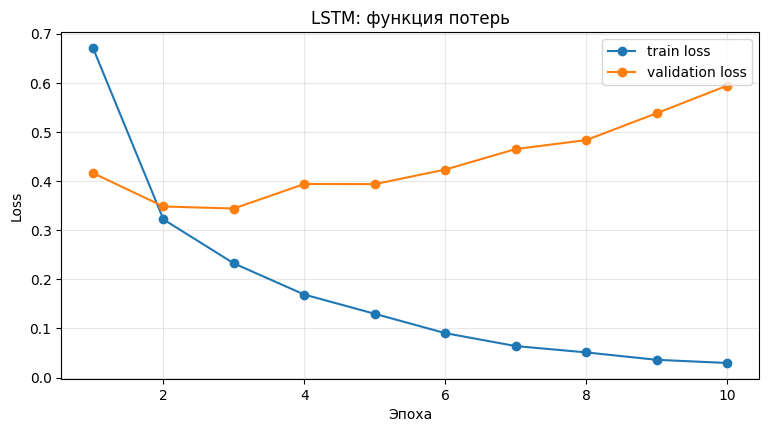

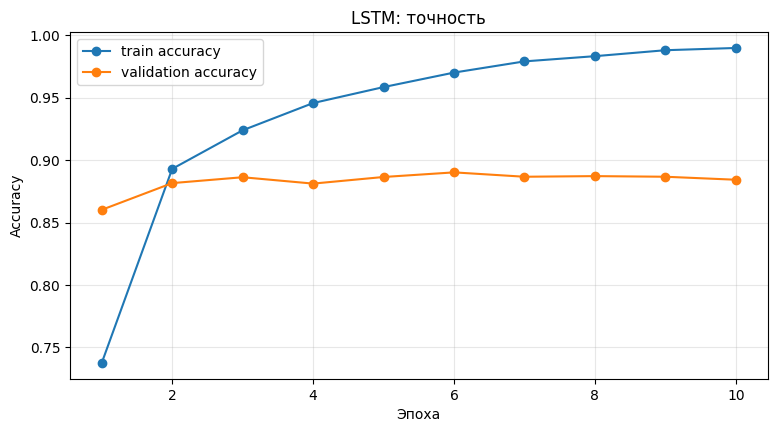

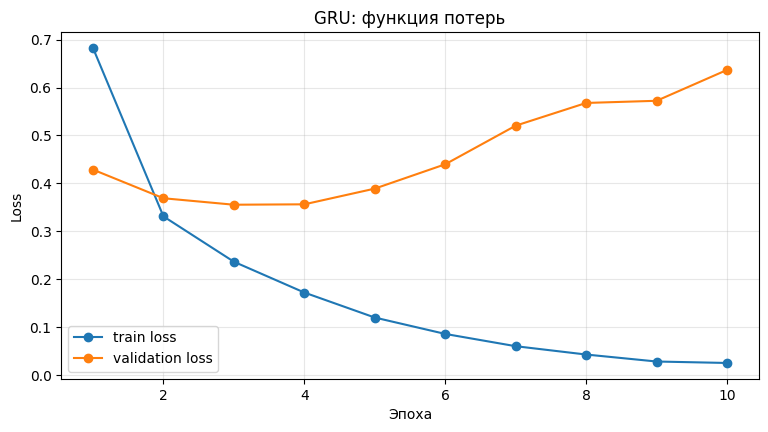

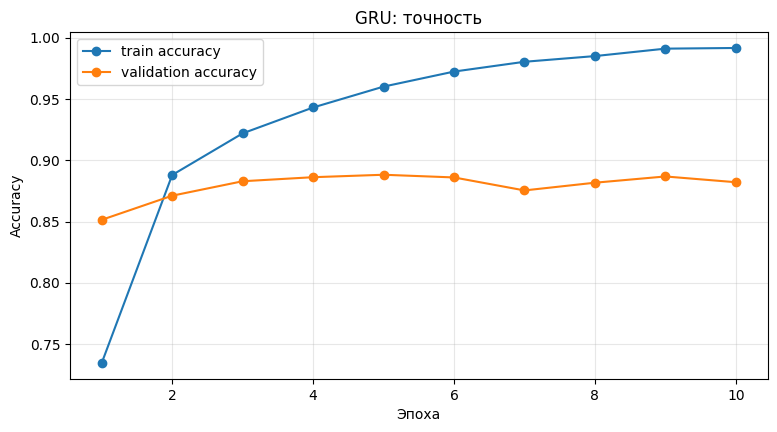

In [67]:
plot_history(lstm_metrics, "LSTM")
plot_history(gru_metrics, "GRU")

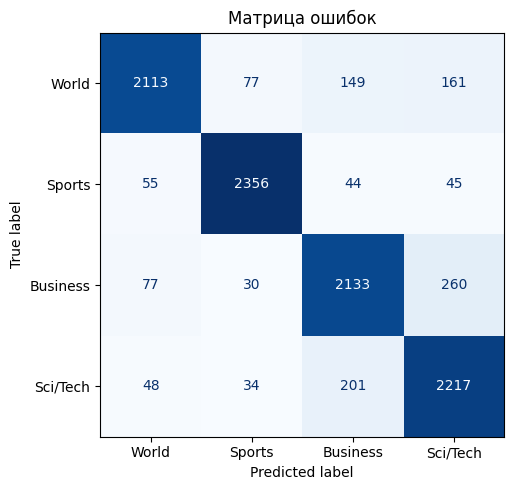

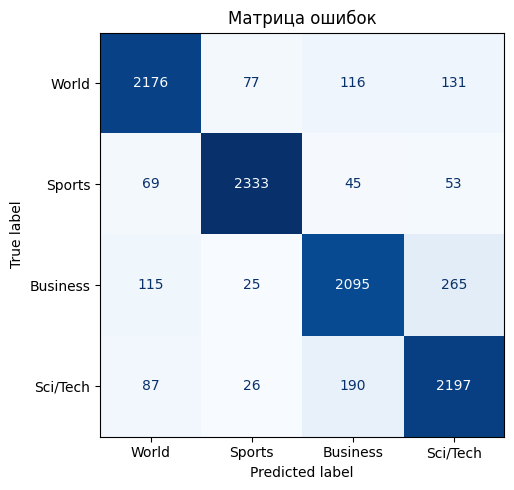

In [70]:
plot_matrix(lstm_best_model, test_sequence_loader)
plot_matrix(gru_best_model, test_sequence_loader)

**Исследование:**

1. Дала ли рекуррентная обработка прирост качества относительно усреднения embedding?
2. Какая модель обучалась быстрее?
3. Есть ли признаки переобучения?

## Измерение времени прямого прохода

Время обучения включает и forward, и backward, обновление параметров, работу DataLoader и валидацию. Чтобы отдельно оценить скорость предсказания, измерим время прямого прохода одного фиксированного батча.

Для корректного замера на CUDA необходимо синхронизировать устройство до и после измеряемого участка: операции GPU выполняются асинхронно относительно Python.

In [95]:
# Измеряем среднее время инференса одного батча с учётом синхронизации CUDA.
import time


@torch.inference_mode()
def measure_inference_time(
    model: nn.Module, batch: tuple[TensorPair, torch.Tensor], repeats: int = 100
) -> float:
    model.eval()
    data, _ = batch
    data = [item.to(device) for item in data]

    for _ in range(5):
        model(*data)
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()
    for _ in range(repeats):
        model(*data)
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    return (time.perf_counter() - start) * 1000 / repeats


embedding_sample_batch = next(iter(validation_embedding_loader))
sequence_sample_batch = next(iter(validation_sequence_loader))

models = {
    "EmbeddingBag": embedding_bag_best_model,
    "RNN": rnn_best_model,
    "LSTM": lstm_best_model,
    "GRU": gru_best_model,
}

inference_times = []
for name, model in models.items():
    sample_batch = (
        embedding_sample_batch if name == "EmbeddingBag" else sequence_sample_batch
    )

    inference_times.append(
        {
            "Модель": name,
            "Forward, мс/батч": measure_inference_time(model, sample_batch),
        }
    )

inference_table = pd.DataFrame(inference_times)
inference_table.sort_values(by=inference_table.columns[1])

,Модель,"Forward, мс/батч"
0,EmbeddingBag,0.212229
3,GRU,13.122329
2,LSTM,13.344851
1,RNN,14.160089


**Небольшое исследование.** Какая модель показала себя лучше всего по скорости, а какая хуже? Как можно объяснить различия в скорости моделей?

## Что видит усреднённая модель и что видит RNN

Соберём все новости, где модели расходятся. Для каждой новости сравним предсказания baseline и рекуррентной модели. 

**Ограничение:** рекуррентная сеть не понимает грамматику так, как человек. Она обучает статистические зависимости между токенами и метками на данном корпусе. Успешная классификация не доказывает, что модель выучила причинно-следственные или лингвистические правила.

In [98]:
# Строим сравнительную таблицу предсказаний EmbeddingBag и RNN.

y_true, eb_preds, _ = collect_predictions(
    embedding_bag_best_model, test_embedding_loader, device
)
_, rnn_preds, _ = collect_predictions(rnn_best_model, test_sequence_loader, device)

comparison_examples = []

for index, (true, eb_pred, rnn_pred) in enumerate(zip(y_true, eb_preds, rnn_preds)):
    if eb_pred != rnn_pred:
        comparison_examples.append(
            {
                "Истинный класс": CLASS_NAMES[true],
                "EmbeddingBag": CLASS_NAMES[eb_pred],
                "RNN": CLASS_NAMES[rnn_pred],
                "Текст": test[index]["text"],
            }
        )

comparison = pd.DataFrame(comparison_examples)
comparison.sample(10)

,Истинный класс,EmbeddingBag,RNN,Текст
674,World,Sci/Tech,Sports,Welcome to New York. Now Go Hail a Cab. You sa...
34,World,World,Business,"Europe, Islam #39;s New Front Line: The Nether..."
354,Business,Business,Sci/Tech,Ex-CA chief pleads not guilty to fraud This fo...
303,World,World,Sci/Tech,Lockheed and the Future of Warfare In the post...
625,World,World,Sci/Tech,Russia jails scientist for spying A Russian ph...
357,Sci/Tech,Business,Sci/Tech,Once a spammer? The lawyer who headed a lawsui...
808,Sports,Sports,Sci/Tech,Red Bull saves 300 British jobs - and Coulthar...
315,Business,Business,Sports,No allocation strategy is perfect for everyone...
496,Sci/Tech,Sci/Tech,Business,PeopleSoft Raises Estimates for Quarter (AP) A...
570,Sci/Tech,World,Sci/Tech,NSA Prodded to Look Beyond Its Fortress The Na...


**Исследование.** Посмотрите, есть ли в тексте отрицания, выражения вроде `not expected`, `company reports`, `team defeats` и т. п. Определите, каков порядок упоминания объектов. Как это может объяснить расхождение в предсказанных классах?

## Контрольные вопросы

1. Чем последовательность отличается от неупорядоченного набора признаков?
2. Почему перестановка токенов не меняет представление `EmbeddingBag` в режиме `mean`?
3. Для чего нужны `<PAD>` и `<UNK>`? Почему словарь следует строить только на train?
4. Чем `nn.Embedding` отличается от `nn.EmbeddingBag` по форме результата и назначению?
5. Что хранит скрытое состояние RNN и как оно обновляется на очередном шаге?
6. Почему веса рекуррентной ячейки разделяются между временными шагами?
7. Что происходит при разворачивании RNN во времени и почему обратное распространение называется BPTT?
8. Чем опасны затухание и взрыв градиентов? 
9. Почему padding может искажать итоговое скрытое состояние, если не использовать реальные длины последовательностей?
10. Для чего предназначен `pack_padded_sequence`?
11. Какие дополнительные состояния и ворота есть у LSTM?
12. Чем GRU отличается от LSTM?
13. Почему двунаправленная RNN может использовать контекст как слева, так и справа от текущего токена?